In [7]:
import pandas as pd
df=pd.read_csv("/content/_Reliance-Fresh company.csv")

In [8]:
try:
    print(df.head())
except NameError:
    print("Error: The variable 'df' is not defined. Please run a cell to load your dataset first.")

                                  Keyword             Name  \
0  "Reliance Fresh grocery store Chennai"  Fresh Signature   
1  "Reliance Fresh grocery store Chennai"   Reliance Fresh   
2  "Reliance Fresh grocery store Chennai"   Reliance Fresh   
3  "Reliance Fresh grocery store Chennai"   Reliance Fresh   
4  "Reliance Fresh grocery store Chennai"   Reliance Fresh   

                                        Full_Address           Street_Address  \
0  No24  Raja Annamalai Rd  Purasaiwakkam  Chenna...  No24  Raja Annamalai Rd   
1  4  G R Plaza 20  1&2  N Usman Rd  T. Nagar  Ch...                        4   
2  87  67  Avvai Shanmugam Salai  Balaji Nagar  R...                       87   
3  No  27  1327  18th Main Rd  Anna Nagar West  K...                   No  27   
4  No.15  Old No.22 New  11th Ave  Ashok Nagar  C...                    No.15   

      City     Zip                Municipality       State Country  \
0  Chennai  600084  Chennai  Tamil Nadu 600084  Tamil Nadu      IN   


In [9]:
df.drop(['Country', 'Timezone','Meta Description','Meta Keywords','Uuid'], axis=1, inplace=True)


In [10]:
df.drop(['Saturday','Sunday','Monday','Tuesday','Wednesday','Thursday','Friday','Sub_Title','Phone_1','Business Status','Phone From WEBSITE','Email From WEBSITE','Facebook URL','Twitter URL','Instagram URL','Youtube URL'], axis=1, inplace=True)


In [11]:
df.dtypes


,0
Keyword,object
Name,object
Full_Address,object
Street_Address,object
City,object
Zip,object
Municipality,object
State,object
Website,object
Domain,object


In [12]:
df.describe(include='all')

,Keyword,Name,Full_Address,Street_Address,City,Zip,Municipality,State,Website,Domain,...,Image_URL,Favicon,Review_URL,Accessibility,Amenities,Service options,Payments,Offerings,Recycling,Crowd
count,148,148,148,148,148,148,148,148,148,148,...,148,148,148,93,11,124,142,11,10,5
unique,3,27,148,147,24,100,142,3,33,5,...,145,33,134,8,2,5,6,2,1,1
top,"""Reliance Fresh Bangalore""",Reliance Fresh,No24 Raja Annamalai Rd Purasaiwakkam Chenna...,4,Bengaluru,560043,Chennai Tamil Nadu 600056,Karnataka,http://storelocator.ril.com/Retail.aspx,storelocator.ril.com,...,,https://t1.gstatic.com/faviconV2?client=SOCIAL...,,Wheelchair-accessible car park | Wheelchair-ac...,Toilets | Wi-Fi | Wi-Fi,No-contact delivery | Delivery | In-store pick...,Credit cards | Mobile Wallets,Organic products | Prepared foods | Salad bar,Plastic bottles,LGBTQ+ friendly
freq,60,72,1,2,55,6,3,60,43,73,...,4,43,15,63,10,79,64,10,10,5
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Keyword                     148 non-null    object 
 1   Name                        148 non-null    object 
 2   Full_Address                148 non-null    object 
 3   Street_Address              148 non-null    object 
 4   City                        148 non-null    object 
 5   Zip                         148 non-null    object 
 6   Municipality                148 non-null    object 
 7   State                       148 non-null    object 
 8   Website                     148 non-null    object 
 9   Domain                      148 non-null    object 
 10  First_category              148 non-null    object 
 11  Second_category             148 non-null    object 
 12  Claimed_google_my_business  148 non-null    object 
 13  Reviews_count               133 non

In [14]:
df.drop_duplicates(inplace=True)


In [15]:
# Fill missing values in 'average_rating' and 'reviews_count' with 0
df['Average_rating'].fillna(0, inplace=True)
df['Reviews_count'].fillna(0, inplace=True)


/tmp/ipykernel_1377/4096396855.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Average_rating'].fillna(0, inplace=True)
/tmp/ipykernel_1377/4096396855.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usin

In [16]:
df = df[df['Average_rating'] <= 5]  # Assuming ratings are on a scale of 1 to 5


In [17]:
# Function to standardize text without altering already correct format
def standardize_text(text):
    if pd.isna(text):  # Check for NaN values
        return text
    # Strip leading/trailing whitespace
    text = text.strip()

    # Only change the text if it's not already properly formatted
    if not (text[0].isupper() and text[1:].islower()):
        text = text.lower().capitalize()

    return text

In [18]:
df['Keyword'] = df['Keyword'].apply(standardize_text)

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium


In [20]:
# 1. basic statistics
basic_stats = df[['Average_rating', 'Reviews_count']].describe()
print("Basic Statistics:\n", basic_stats)

Basic Statistics:
        Average_rating  Reviews_count
count      148.000000     148.000000
mean         3.316216     909.797297
std          1.256388     984.301693
min          0.000000       0.000000
25%          3.600000      41.000000
50%          3.800000     685.000000
75%          3.900000    1325.000000
max          5.000000    4559.000000


In [21]:

top_rated = df.sort_values(by='Average_rating', ascending=False).head(10)
print("\nTop 10 Products by Rating:\n", top_rated[['Keyword', 'Average_rating', 'State']])


Top 10 Products by Rating:
                                     Keyword  Average_rating       State
110              "reliance fresh bangalore"             5.0   Karnataka
78                     Reliance fresh kochi             5.0      Kerala
107              "reliance fresh bangalore"             4.3   Karnataka
75                     Reliance fresh kochi             4.2      Kerala
71                     Reliance fresh kochi             4.2      Kerala
55   "reliance fresh grocery store chennai"             4.2  Tamil Nadu
73                     Reliance fresh kochi             4.2      Kerala
33   "reliance fresh grocery store chennai"             4.1  Tamil Nadu
47   "reliance fresh grocery store chennai"             4.1  Tamil Nadu
57                     Reliance fresh kochi             4.1      Kerala


In [22]:

bottom_rated = df.sort_values(by='Average_rating').head(10)
print("\nBottom 10 Products by Rating:\n", bottom_rated[['Keyword', 'Average_rating', 'State']])


Bottom 10 Products by Rating:
                                     Keyword  Average_rating       State
31   "reliance fresh grocery store chennai"             0.0  Tamil Nadu
29   "reliance fresh grocery store chennai"             0.0  Tamil Nadu
58                     Reliance fresh kochi             0.0      Kerala
35   "reliance fresh grocery store chennai"             0.0  Tamil Nadu
123              "reliance fresh bangalore"             0.0   Karnataka
117              "reliance fresh bangalore"             0.0   Karnataka
116              "reliance fresh bangalore"             0.0   Karnataka
114              "reliance fresh bangalore"             0.0   Karnataka
102              "reliance fresh bangalore"             0.0   Karnataka
106              "reliance fresh bangalore"             0.0   Karnataka


In [23]:
correlation_matrix = df[['Average_rating', 'Reviews_count']].corr()
print("\nCorrelation Matrix:\n", correlation_matrix)


Correlation Matrix:
                 Average_rating  Reviews_count
Average_rating         1.00000        0.38749
Reviews_count          0.38749        1.00000


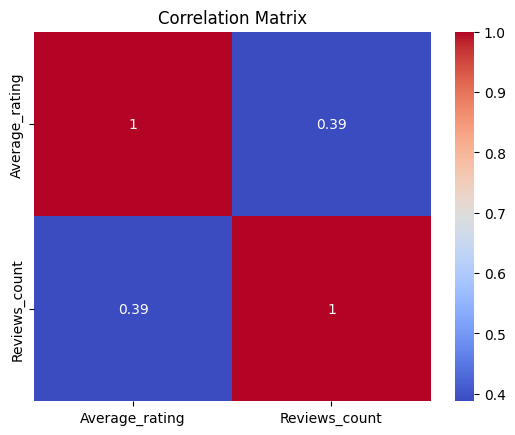

In [24]:

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


In [25]:
claimed_vs_unclaimed = df.groupby('Claimed_google_my_business').agg({
    'Average_rating': ['mean', 'std', 'count'],
    'Reviews_count': ['mean', 'std', 'sum']
}).reset_index()


In [26]:
claimed_vs_unclaimed.columns = [
    'Claimed',
    'Avg Rating Mean', 'Avg Rating Std', 'Total Businesses',
    'Avg Reviews Count', 'Reviews Count Std', 'Total Reviews',
]

In [27]:

print("Analysis Between Claimed vs. Unclaimed Businesses:\n")
print(claimed_vs_unclaimed)

Analysis Between Claimed vs. Unclaimed Businesses:

  Claimed  Avg Rating Mean  Avg Rating Std  Total Businesses  \
0      No         2.321277        1.786049                47   
1     Yes         3.779208        0.413840               101   

   Avg Reviews Count  Reviews Count Std  Total Reviews  
0         424.085106         948.520927        19932.0  
1        1135.821782         920.799831       114718.0  


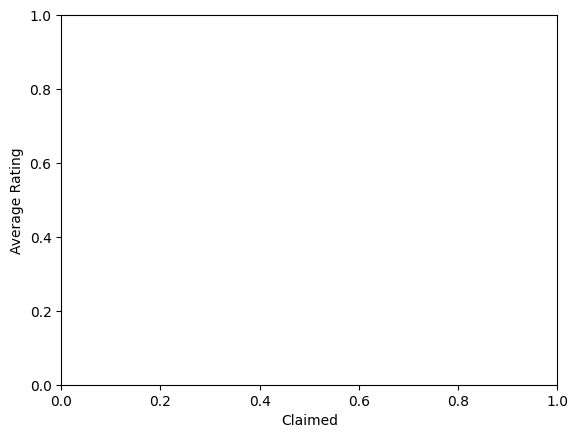

In [28]:
# 4. Visualization (optional, if you want to visualize the results)
plt.ylabel('Average Rating')
plt.xlabel('Claimed')
plt.show()


In [29]:
import geopandas as gpd

# Convert 'Longitude' column to string type before using .str accessor
df['Longitude'] = df['Longitude'].astype(str).str.replace('Lng ', '').astype(float)

# Remove 'Lat ' prefix from Latitude values and convert to float
df['Latitude'] = df['Latitude'].astype(str).str.replace('Lat ', '').astype(float) # Fix: Clean the 'Latitude' column

# Convert the DataFrame to a GeoDataFrame
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.Longitude, df.Latitude))

# Ensure the GeoDataFrame has the correct Coordinate Reference System (CRS)
gdf.crs = "EPSG:4326"  # WGS84

In [30]:
!pip install contextily

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [contextily]


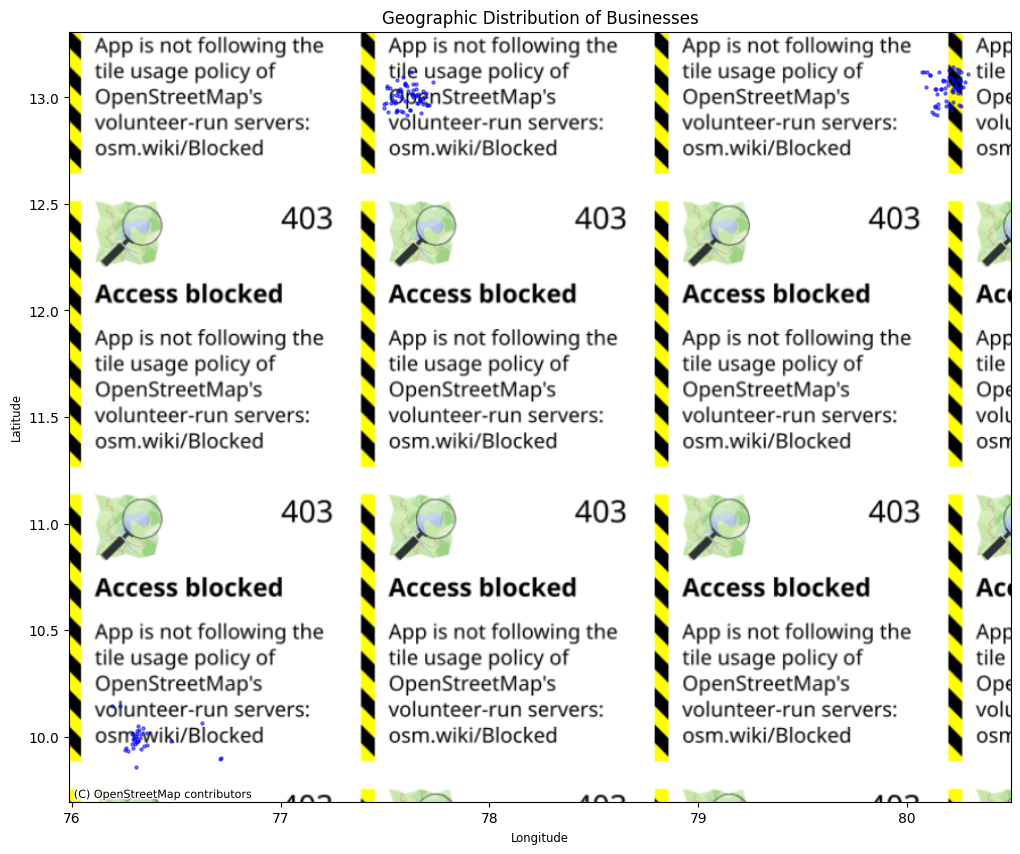

In [31]:
!pip install --upgrade contextily  # Upgrade contextily to the latest version   #### Visualize the Geographic Distribution

import matplotlib.pyplot as plt
import contextily as ctx
# Plot all businesses
fig, ax = plt.subplots(figsize=(15, 10))
gdf.plot(ax=ax, color='blue', alpha=0.5, markersize=5)

# Use a different provider from contextily
ctx.add_basemap(ax, crs=gdf.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)  # Try OpenStreetMap.Mapnik

# Add title and labels
plt.title('Geographic Distribution of Businesses')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [32]:
# Create a map centered at the average of the latitudes and longitudes
m = folium.Map(location=[df['Latitude'].mean(), df['Longitude'].mean()], zoom_start=12)

# Add markers for each location in the DataFrame
for index, row in df.iterrows():
    folium.Marker([row['Latitude'], row['Longitude']], popup=row['Name']).add_to(m)

# Display map
m

In [33]:
from math import radians, sin, cos, sqrt, atan2

# Haversine function
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # Radius of the Earth in kilometers
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat / 2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    distance = R * c
    return distance
# Reference point (e.g., some central point)
ref_lat, ref_lon = 13.0803, 80.2547

# Apply the haversine function for each row in the DataFrame
df['Distance_km'] = df.apply(lambda row: haversine(ref_lat, ref_lon, row['Latitude'], row['Longitude']), axis=1)

df

,Keyword,Name,Full_Address,Street_Address,City,Zip,Municipality,State,Website,Domain,...,Favicon,Review_URL,Accessibility,Amenities,Service options,Payments,Offerings,Recycling,Crowd,Distance_km
0,"""reliance fresh grocery store chennai""",Fresh Signature,No24 Raja Annamalai Rd Purasaiwakkam Chenna...,No24 Raja Annamalai Rd,Chennai,600084,Chennai Tamil Nadu 600084,Tamil Nadu,http://storelocator.ril.com/#,storelocator.ril.com,...,https://t1.gstatic.com/faviconV2?client=SOCIAL...,https://search.google.com/local/reviews?placei...,Wheelchair-accessible seating | Wheelchair-acc...,Toilets | Wi-Fi | Wi-Fi,No-contact delivery | Delivery | In-store pick...,Cheques | Credit cards | Debit cards | Google ...,Organic products | Prepared foods | Salad bar,Plastic bottles,LGBTQ+ friendly,0.000000
1,"""reliance fresh grocery store chennai""",Reliance Fresh,4 G R Plaza 20 1&2 N Usman Rd T. Nagar Ch...,4,Chennai,600017,G R Plaza 20,Tamil Nadu,https://relianceretail.com/reliance-fresh.html,relianceretail.com,...,https://t1.gstatic.com/faviconV2?client=SOCIAL...,https://search.google.com/local/reviews?placei...,Wheelchair-accessible car park | Wheelchair-ac...,NaN,No-contact delivery | Delivery | In-store pick...,Credit cards | Mobile Wallets,NaN,NaN,NaN,3.904663
2,"""reliance fresh grocery store chennai""",Reliance Fresh,87 67 Avvai Shanmugam Salai Balaji Nagar R...,87,Chennai,600014,67 Avvai Shanmugam Salai,Tamil Nadu,http://storelocator.ril.com/Retail.aspx,storelocator.ril.com,...,https://t1.gstatic.com/faviconV2?client=SOCIAL...,https://search.google.com/local/reviews?placei...,Wheelchair-accessible car park | Wheelchair-ac...,NaN,No-contact delivery | Delivery | In-store pick...,Credit cards | Debit cards | Mobile Wallets | ...,NaN,NaN,NaN,3.965986
3,"""reliance fresh grocery store chennai""",Reliance Fresh,No 27 1327 18th Main Rd Anna Nagar West K...,No 27,Chennai,600040,1327 18th Main Rd,Tamil Nadu,http://storelocator.ril.com/Retail.aspx,storelocator.ril.com,...,https://t1.gstatic.com/faviconV2?client=SOCIAL...,https://search.google.com/local/reviews?placei...,NaN,NaN,No-contact delivery | Delivery | In-store pick...,Credit cards | Debit cards | Mobile Wallets | ...,NaN,NaN,NaN,6.001981
4,"""reliance fresh grocery store chennai""",Reliance Fresh,No.15 Old No.22 New 11th Ave Ashok Nagar C...,No.15,Chennai,600083,Old No.22 New,Tamil Nadu,http://storelocator.ril.com/Retail.aspx#,storelocator.ril.com,...,https://t1.gstatic.com/faviconV2?client=SOCIAL...,https://search.google.com/local/reviews?placei...,Wheelchair-accessible entrance,NaN,No-contact delivery | Delivery | In-store pick...,Credit cards | Mobile Wallets,NaN,NaN,NaN,6.818277
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,"""reliance fresh bangalore""",Reliance SMART Superstore,Khata No 941/161 & 204/01 Sy No 161 & 204 Ben...,Khata No 941/161 & 204/01 Sy No 161 & 204,Bengaluru,560075,Bengaluru Karnataka 560075,Karnataka,https://stores.reliancesmartbazaar.com/relianc...,stores.reliancesmartbazaar.com,...,https://t1.gstatic.com/faviconV2?client=SOCIAL...,https://search.google.com/local/reviews?placei...,NaN,NaN,No-contact delivery | Delivery | In-store pick...,Credit cards | Mobile Wallets,NaN,NaN,NaN,278.965219
144,"""reliance fresh bangalore""",Reliance Fresh,55/373 100 Feet Ring Rd Vysya Bank Colony स...,55/373,Bengaluru,560076,100 Feet Ring Rd,Karnataka,https://relianceretail.com/reliance-fresh.html,relianceretail.com,...,https://t1.gstatic.com/faviconV2?client=SOCIAL...,https://search.google.com/local/reviews?placei...,Wheelchair-accessible car park | Wheelchair-ac...,NaN,No-contact delivery | Delivery | In-store pick...,Credit cards | Debit cards | Mobile Wallets,NaN,NaN,NaN,287.697757
145,"""reliance fresh bangalore""",Reliance Fresh,Municipal No. 289/A 12Th Loop Road 17Th Cross...,Municipal No. 289/A 12Th Loop Road 17Th Cross,Bengaluru,560098,Rd,Karnataka,https://storelocator.ril.com/Retail.aspx,storelocator.ril.com,...,https://t1.g

In [34]:
# Create an empty DataFrame to store distances
distance_matrix = pd.DataFrame(index=df['Name'], columns=df['Name'])

# Calculate distances between each pair of locations
for i, row1 in df.iterrows():
    for j, row2 in df.iterrows():
        distance_matrix.loc[row1['Name'], row2['Name']] = haversine(row1['Latitude'], row1['Longitude'], row2['Latitude'], row2['Longitude'])

distance_matrix

Name,Fresh Signature,Reliance Fresh,Reliance Fresh,Reliance Fresh,Reliance Fresh,Reliance Fresh,Reliance Smart Point,Reliance Fresh,Reliance Fresh,Reliance Fresh,...,Reliance Fresh,Reliance SMART Bazaar,Reliance Smart Point,Reliance Fresh signature,Reliance SMART Bazaar,Reliance SMART Superstore,Reliance Fresh,Reliance Fresh,Reliance Smart Point,Reliance Smart Point
Name,,,,,,,,,,,,,,,,,,,,,
Fresh Signature,0.0,17.016345,17.016345,17.016345,17.016345,17.016345,13.947699,17.016345,17.016345,17.016345,...,17.016345,1.302359,13.947699,9.852673,1.302359,5.973,17.016345,17.016345,13.947699,13.947699
Reliance Fresh,17.016345,0.0,0.0,0.0,0.0,0.0,3.865224,0.0,0.0,0.0,...,0.0,18.294167,3.865224,16.654875,18.294167,18.553992,0.0,0.0,3.865224,3.865224
Reliance Fresh,17.016345,0.0,0.0,0.0,0.0,0.0,3.865224,0.0,0.0,0.0,...,0.0,18.294167,3.865224,16.654875,18.294167,18.553992,0.0,0.0,3.865224,3.865224
Reliance Fresh,17.016345,0.0,0.0,0.0,0.0,0.0,3.865224,0.0,0.0,0.0,...,0.0,18.294167,3.865224,16.654875,18.294167,18.553992,0.0,0.0,3.865224,3.865224
Reliance Fresh,17.016345,0.0,0.0,0.0,0.0,0.0,3.865224,0.0,0.0,0.0,...,0.0,18.294167,3.865224,16.654875,18.294167,18.553992,0.0,0.0,3.865224,3.865224
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Reliance SMART Superstore,5.973,18.553992,18.553992,18.553992,18.553992,18.553992,14.845507,18.553992,18.553992,18.553992,...,18.553992,5.730965,14.845507,5.054657,5.730965,0.0,18.553992,18.553992,14.845507,14.845507
Reliance Fresh,17.016345,0.0,0.0,0.0,0.0,0.0,3.865224,0.0,0.0,0.0,...,0.0,18.294167,3.865224,16.654875,18.294167,18.553992,0.0,0.0,3.865224,3.865224
Reliance Fresh,17.016345,0.0,0.0,0.0,0.0,0.0,3.865224,0.0,0.0,0.0,...,0.0,18.294167,3.865224,16.654875,18.294167,18.553992,0.0,0.0,3.865224,3.865224


The location with the highest average distance is: RELIANCE Fresh Signature


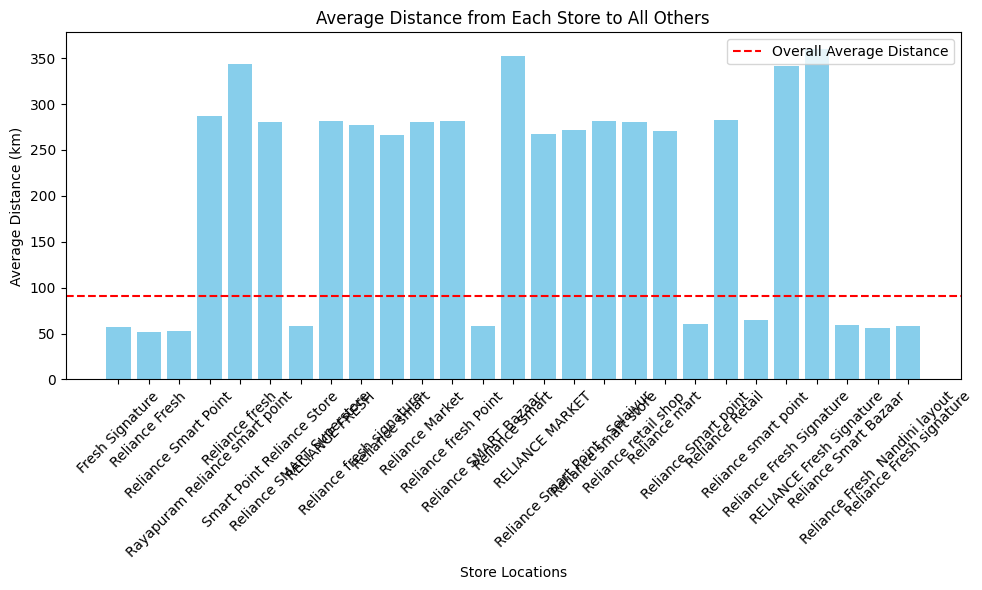

In [35]:
# Calculate average distance from each location to all others
distance_matrix['Average_Distance'] = distance_matrix.mean(axis=1)

# Find the store with the maximum average distance
max_avg_distance_store = distance_matrix['Average_Distance'].idxmax()
print(f"The location with the highest average distance is: {max_avg_distance_store}")

# Plot the average distances for each store
plt.figure(figsize=(10, 6))
plt.bar(distance_matrix.index, distance_matrix['Average_Distance'], color='skyblue')
plt.axhline(y=distance_matrix['Average_Distance'].mean(), color='r', linestyle='--', label='Overall Average Distance')

plt.title('Average Distance from Each Store to All Others')
plt.xlabel('Store Locations')
plt.ylabel('Average Distance (km)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()


In [36]:
import numpy as np
from sklearn.cluster import DBSCAN

# Coordinates in radians (required for the haversine metric)
coords = np.radians(gdf[['Latitude', 'Longitude']].values)
KMS_PER_RADIAN = 6371.0

# Compare a few neighbourhood sizes (eps is given in km, then converted to radians)
for eps_km in [1, 2, 5, 10]:
    labels = DBSCAN(eps=eps_km / KMS_PER_RADIAN, min_samples=3,
                    metric='haversine', algorithm='ball_tree').fit_predict(coords)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"eps = {eps_km} km -> {n_clusters} clusters, {(labels == -1).sum()} noise points")

# Final model: stores within ~2 km of each other, at least 3 stores per cluster
EPS_KM = 2
db = DBSCAN(eps=EPS_KM / KMS_PER_RADIAN, min_samples=3,
            metric='haversine', algorithm='ball_tree')
gdf['cluster'] = db.fit_predict(coords)

print("\nStores per cluster (-1 = not in any cluster):")
print(gdf['cluster'].value_counts().sort_index())
gdf[['Name', 'City', 'cluster']].head(10)


eps = 1 km -> 5 clusters, 133 noise points
eps = 2 km -> 18 clusters, 60 noise points
eps = 5 km -> 3 clusters, 9 noise points
eps = 10 km -> 3 clusters, 6 noise points

Stores per cluster (-1 = not in any cluster):
cluster
-1     60
 0      3
 1     11
 2      3
 3      4
 4      3
 5      4
 6      3
 7      3
 8     15
 9      3
 10     6
 11     4
 12     4
 13     3
 14     7
 15     4
 16     3
 17     5
Name: count, dtype: int64


,Name,City,cluster
0,Fresh Signature,Chennai,0
1,Reliance Fresh,Chennai,1
2,Reliance Fresh,Chennai,-1
3,Reliance Fresh,Chennai,1
4,Reliance Fresh,Chennai,1
5,Reliance Fresh,Chennai,-1
6,Reliance Smart Point,Chennai,-1
7,Reliance Fresh,Chennai,-1
8,Reliance Fresh,Chennai,1
9,Reliance Fresh,Chennai,2


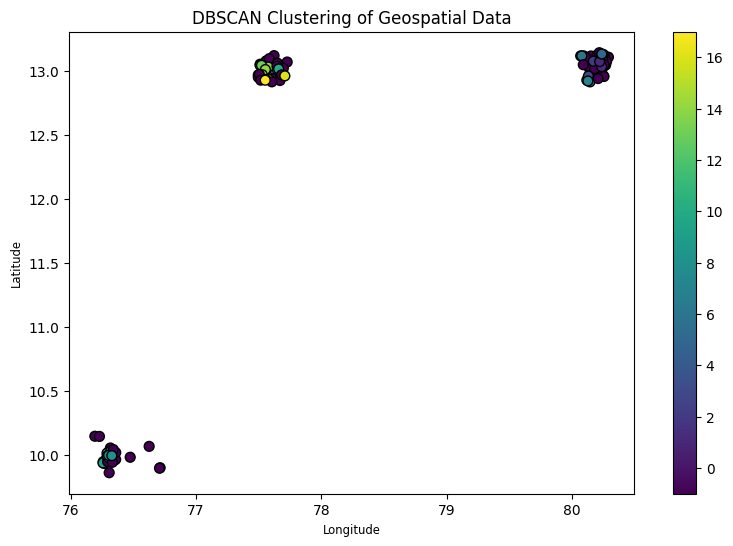

In [37]:
# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
gdf.plot(ax=ax, column='cluster', # Use column to specify the values for coloring
         cmap='viridis', # Use cmap for colormap
         edgecolor='black', markersize=50, legend=True)

# Adding labels
# Check if 'name' column exists before accessing it
if 'name' in gdf.columns:
    for idx, row in gdf.iterrows():
        ax.text(row.geometry.x, row.geometry.y, row['name'], fontsize=12, ha='right')

ax.set_title('DBSCAN Clustering of Geospatial Data')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

plt.show()

In [38]:
# Interactive map of stores coloured by DBSCAN cluster (grey = not in any cluster)
palette = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 'cadetblue',
           'darkgreen', 'pink', 'black', 'lightblue', 'beige']

m = folium.Map(location=[gdf['Latitude'].mean(), gdf['Longitude'].mean()], zoom_start=6)

for _, row in gdf.iterrows():
    label = int(row['cluster'])
    colour = 'gray' if label == -1 else palette[label % len(palette)]
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=6,
        color=colour,
        fill=True,
        fill_color=colour,
        fill_opacity=0.7,
        popup=f"{row['Name']} (cluster {label})"
    ).add_to(m)

# Zoom the map to fit all stores
m.fit_bounds([[gdf['Latitude'].min(), gdf['Longitude'].min()],
              [gdf['Latitude'].max(), gdf['Longitude'].max()]])

# Save map to HTML file and display it
m.save('clusters_map.html')
m


In [39]:
import pandas as pd
df=pd.read_csv("/content/BigBasket company.csv")

In [40]:

df.drop(['Saturday','Sunday','Monday','Tuesday','Wednesday','Thursday','Friday','Sub_Title','Phone_1','Business Status','Phone From WEBSITE'], axis=1, inplace=True)
df.drop(['Country', 'Timezone','Meta Description','Meta Keywords','Uuid'], axis=1, inplace=True)



In [41]:
df.dtypes

,0
Keyword,object
Name,object
Full_Address,object
Street_Address,object
City,object
Zip,object
Municipality,object
State,object
Website,object
Domain,object


In [42]:
df.drop_duplicates(inplace=True)

In [43]:
# Fill missing values in 'average_rating' and 'reviews_count' with 0
df['Average_rating'].fillna(0, inplace=True)
df['Reviews_count'].fillna(0, inplace=True)

/tmp/ipykernel_1377/1182019857.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Average_rating'].fillna(0, inplace=True)
/tmp/ipykernel_1377/1182019857.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usin

In [44]:
df = df[df['Average_rating'] <= 5]  # Assuming ratings are on a scale of 1 to 5

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium


In [46]:
# 1. Calculate basic statistics
basic_stats = df[['Average_rating', 'Reviews_count']].describe()
print("Basic Statistics:\n", basic_stats)

Basic Statistics:
        Average_rating  Reviews_count
count      109.000000     109.000000
mean         3.690826     165.770642
std          1.365348     799.898635
min          0.000000       0.000000
25%          3.700000       3.000000
50%          4.100000      13.000000
75%          4.400000     174.000000
max          5.000000    8293.000000


In [47]:
# 2. Top and Bottom Performers
# Top 10 based on average rating
top_rated = df.sort_values(by='Average_rating', ascending=False).head(10)
print("\nTop 10 Products by Rating:\n", top_rated[['Keyword', 'Average_rating', 'State']]) # Removed extra space before column names


Top 10 Products by Rating:
                              Keyword  Average_rating           State
3    BigBasket grocery store chennai             5.0      Tamil Nadu
38                  BigBasket mysore             5.0      Tamil Nadu
25   BigBasket supermarket hyderabad             5.0       Telangana
68              BigBasket Bangalore"             5.0       Karnataka
97              BigBasket Bangalore"             5.0       Karnataka
78              BigBasket Bangalore"             5.0       Karnataka
79              BigBasket Bangalore"             5.0       Karnataka
87              BigBasket Bangalore"             5.0       Karnataka
96              BigBasket Bangalore"             5.0       Karnataka
105                 bigbasket guntur             5.0  Andhra Pradesh


In [48]:
# Bottom 10 based on average rating
bottom_rated = df.sort_values(by='Average_rating').head(10)
print("\nBottom 10 Products by Rating:\n", bottom_rated[['Keyword', 'Average_rating', 'State']])


Bottom 10 Products by Rating:
                              Keyword  Average_rating       State
11   BigBasket grocery store chennai             0.0  Tamil Nadu
9    BigBasket grocery store chennai             0.0  Tamil Nadu
22   BigBasket supermarket hyderabad             0.0   Telangana
32   BigBasket supermarket hyderabad             0.0   Telangana
41                  BigBasket mysore             0.0  Tamil Nadu
84              BigBasket Bangalore"             0.0   Karnataka
95              BigBasket Bangalore"             0.0   Karnataka
70              BigBasket Bangalore"             0.0   Karnataka
82              BigBasket Bangalore"             0.0   Karnataka
108                 bigbasket guntur             0.0            


In [49]:
# 3. Correlation Analysis
correlation_matrix = df[['Average_rating', 'Reviews_count']].corr()
print("\nCorrelation Matrix:\n", correlation_matrix)


Correlation Matrix:
                 Average_rating  Reviews_count
Average_rating         1.00000        0.05115
Reviews_count          0.05115        1.00000


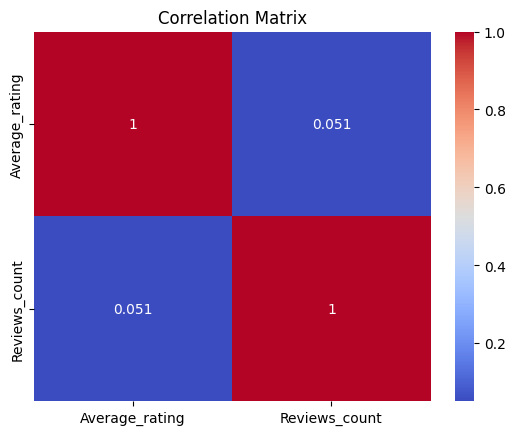

In [50]:
# Heatmap for correlation matrix
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [51]:
#1. Summary Statistics by Claimed vs. Unclaimed
claimed_vs_unclaimed = df.groupby('Claimed_google_my_business').agg({
    'Average_rating': ['mean', 'std', 'count'],
    'Reviews_count': ['mean', 'std', 'sum']
}).reset_index()

In [52]:
# 2. Rename the columns for clarity
claimed_vs_unclaimed.columns = [
    'Claimed',
    'Avg Rating Mean', 'Avg Rating Std', 'Total Businesses',
    'Avg Reviews Count', 'Reviews Count Std', 'Total Reviews',
]

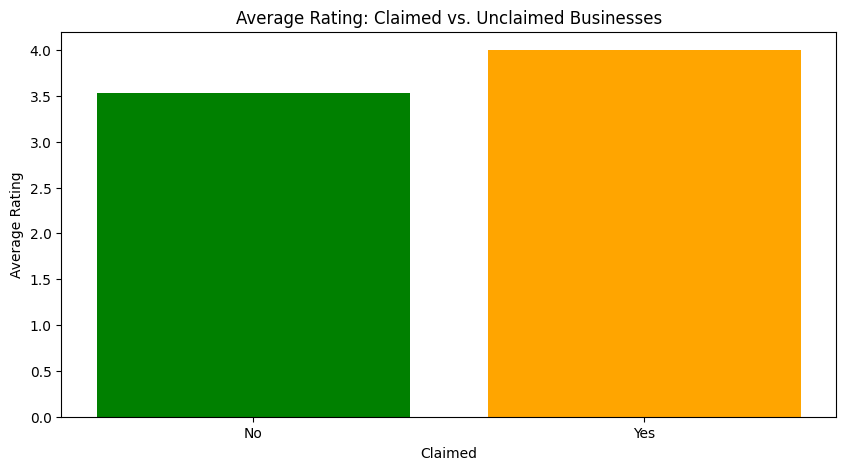

In [53]:
# 4. Visualization (optional, if you want to visualize the results)
import matplotlib.pyplot as plt

# Average Rating Comparison
plt.figure(figsize=(10, 5))
plt.bar(claimed_vs_unclaimed['Claimed'], claimed_vs_unclaimed['Avg Rating Mean'], color=['green', 'orange'])
plt.title('Average Rating: Claimed vs. Unclaimed Businesses')
plt.ylabel('Average Rating')
plt.xlabel('Claimed')
plt.show()


In [54]:
import geopandas as gpd

# Clean the 'Latitude' column first, removing non-numeric values
df['Latitude'] = df['Latitude'].astype(str).str.replace('Lat ', '')
df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce') # Convert to numeric, replacing non-convertible values with NaN

# Clean the 'Longitude' column, removing non-numeric values
df['Longitude'] = df['Longitude'].astype(str).str.replace('Lng ', '')
df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce') # Convert to numeric, replacing non-convertible values with NaN

# Drop rows with NaN values in 'Latitude' or 'Longitude'
df = df.dropna(subset=['Latitude', 'Longitude'])

# Convert the DataFrame to a GeoDataFrame
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.Longitude, df.Latitude))

# Ensure the GeoDataFrame has the correct Coordinate Reference System (CRS)
gdf.crs = "EPSG:4326"  # WGS84

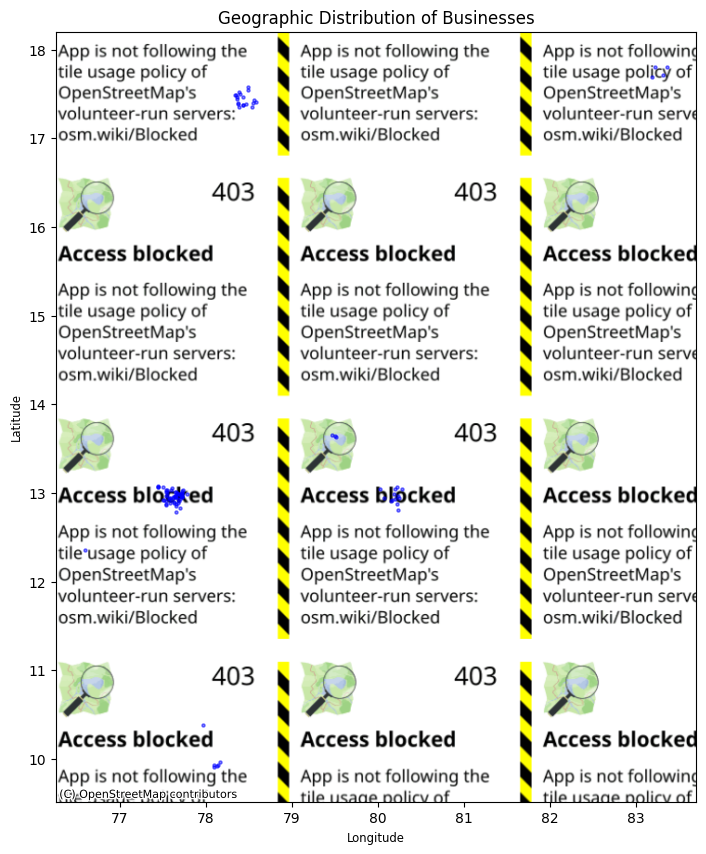

In [55]:
!pip install --upgrade contextily  # Upgrade contextily to the latest version   #### Visualize the Geographic Distribution

import matplotlib.pyplot as plt
import contextily as ctx

# Plot all businesses
fig, ax = plt.subplots(figsize=(15, 10))
gdf.plot(ax=ax, color='blue', alpha=0.5, markersize=5)

# Use a different provider from contextily
ctx.add_basemap(ax, crs=gdf.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)  # Try OpenStreetMap.Mapnik

# Add title and labels
plt.title('Geographic Distribution of Businesses')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [56]:

# Create a map centered at the average of the latitudes and longitudes
m = folium.Map(location=[df['Latitude'].mean(), df['Longitude'].mean()], zoom_start=12)

# Add markers for each location in the DataFrame
for index, row in df.iterrows():
    folium.Marker([row['Latitude'], row['Longitude']], popup=row['Name']).add_to(m)

# Display map
m

In [57]:
from math import radians, sin, cos, sqrt, atan2

# Haversine function
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # Radius of the Earth in kilometers
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat / 2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    distance = R * c
    return distance
# Reference point (e.g., some central point)
ref_lat, ref_lon = 13.0803, 80.2547

# Apply the haversine function for each row in the DataFrame
df['Distance_km'] = df.apply(lambda row: haversine(ref_lat, ref_lon, row['Latitude'], row['Longitude']), axis=1)

df

,Keyword,Name,Full_Address,Street_Address,City,Zip,Municipality,State,Website,Domain,...,Instagram URL,Youtube URL,Accessibility,Service options,Payments,Recycling,Unnamed: 49,Unnamed: 50,Unnamed: 51,Distance_km
0,BigBasket grocery store chennai,Bigbasket 5K - Mylapore,145 71 Dr Natesan Rd Jagadambal Colony Mec...,145,Chennai,600005,71 Dr Natesan Rd,Tamil Nadu,,,...,,,NaN,No-contact delivery | Delivery | In-store pick...,Credit cards | Mobile Wallets,NaN,NaN,NaN,NaN,4.403989
1,BigBasket grocery store chennai,Big basket,Kuthambakkam Tamil Nadu 600124,,Kuthambakkam,600124,,Tamil Nadu,http://www.bigbasket.com/,bigbasket.com,...,NaN,NaN,NaN,No-contact delivery | Delivery | In-store pick...,Credit cards | Mobile Wallets,Batteries | Metal cans | Plastic bags,NaN,NaN,NaN,25.305322
2,BigBasket grocery store chennai,BIG BASKET - NMR DS,Building 106 Chateau D Ampa 110 /3 7 Nelson...,Building 106,Chennai,600029,Chateau D Ampa,Tamil Nadu,http://www.bigbasket.com/,bigbasket.com,...,NaN,NaN,NaN,No-contact delivery | Delivery | Same-day deli...,Credit cards | Mobile Wallets,NaN,NaN,NaN,NaN,3.548987
3,BigBasket grocery store chennai,Big basket,16 Veeraraghavan St near Selver palace NCBS...,16 Veeraraghavan St,Chennai,600061,near Selver palace,Tamil Nadu,https://www.bigbasket.com/,bigbasket.com,...,NaN,NaN,NaN,Delivery,NaN,NaN,NaN,NaN,NaN,12.723552
4,BigBasket grocery store chennai,bigbasket 5K Thoraipakkam,105 Telephone Nagar Perungudi Chennai Tami...,105,Chennai,600096,Chennai Tamil Nadu 600096,Tamil Nadu,,,...,,,NaN,No-contact delivery | Delivery | Same-day deli...,Credit cards | Mobile Wallets,NaN,NaN,NaN,NaN,13.258970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,"BigBasket Bangalore""",Bigbasket dormitory,2G8W+8QV Sri Kanteshwara Nagar Mahalakshmi L...,2G8W+8QV,Bengaluru,,Bengaluru Karnataka 560086,Karnataka,,,...,,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,293.402484
99,"BigBasket Bangalore""",Bigbasket,65 3rd St Austin Town Neelasandra Bengalur...,65 3rd St,Bengaluru,560022,Bengaluru Karnataka 560022,Karnataka,,,...,,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,286.241595
100,"BigBasket Bangalore""",BigBasket B2B Adakimaranahalli,SY NO 13/1 AND NO 15/5 ADAKIMARANAHALLI DASA...,SY NO 13/1 AND NO 15/5 ADAKIMARANAHALLI DASA...,"Bengaluru, Dasanapura",562123,Bengaluru Karnataka 562123,Karnataka,,,...,,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,304.370762
101,"BigBasket Bangalore""",Big basket Ndc,3CGQ+7WQ Unnamed Road Nagarur colony Dasana...,3CGQ+7WQ,Dasanapura,562123,Unnamed Road,Karnataka,,,...,,,Wheelchair-accessible car park,NaN,NaN,NaN,NaN,NaN,NaN,304.876593


In [58]:
# Create an empty DataFrame to store distances
distance_matrix = pd.DataFrame(index=df['Name'], columns=df['Name'])

# Calculate distances between each pair of locations
for i, row1 in df.iterrows():
    for j, row2 in df.iterrows():
        distance_matrix.loc[row1['Name'], row2['Name']] = haversine(row1['Latitude'], row1['Longitude'], row2['Latitude'], row2['Longitude'])

distance_matrix

Name,Bigbasket 5K - Mylapore,Big basket,BIG BASKET - NMR DS,Big basket,bigbasket 5K Thoraipakkam,Bigbasket,Bigbasket Selaiyur,Big Basket Kazhipattur 5K,Big Basket HUB,Bigbasket,...,Big basket Banaswadi,BB NOW BIGBASKET BEGUR,Big basket,BB Now Big Basket seegehalli stores,BB NOW Bigbasket Brookfield,Bigbasket dormitory,Bigbasket,BigBasket B2B Adakimaranahalli,Big basket Ndc,Bigbasket DC2 & Warehouse
Name,,,,,,,,,,,,,,,,,,,,,
Bigbasket 5K - Mylapore,0.0,289.795583,6.30294,289.795583,10.352757,288.340795,20.141196,26.399508,11.954143,288.340795,...,285.442277,287.476102,289.795583,275.000334,277.282124,295.589625,288.340795,306.636437,307.149697,285.810296
Big basket,289.795583,0.0,284.16954,0.0,285.260096,8.049864,277.184887,286.339392,286.244246,8.049864,...,5.085028,15.85957,0.0,14.795577,14.614612,5.961027,8.049864,17.468403,18.123852,27.908472
BIG BASKET - NMR DS,6.30294,284.16954,0.0,284.16954,12.083796,282.795593,19.615193,28.82035,14.278171,282.795593,...,279.842926,282.014628,284.16954,269.37606,271.735269,289.977105,282.795593,300.965675,301.473507,280.486074
Big basket,289.795583,0.0,284.16954,0.0,285.260096,8.049864,277.184887,286.339392,286.244246,8.049864,...,5.085028,15.85957,0.0,14.795577,14.614612,5.961027,8.049864,17.468403,18.123852,27.908472
bigbasket 5K Thoraipakkam,10.352757,285.260096,12.083796,285.260096,0.0,283.550784,10.354392,16.756982,2.297399,283.550784,...,280.823548,282.438584,285.260096,270.469749,272.505049,291.006314,283.550784,302.239069,302.770507,280.397865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Bigbasket dormitory,295.589625,5.961027,289.977105,5.961027,291.006314,9.802403,282.893557,291.98407,291.97889,9.802403,...,10.225723,16.57205,5.961027,20.628134,19.346411,0.0,9.802403,12.632351,13.371376,28.253599
Bigbasket,288.340795,8.049864,282.795593,8.049864,283.550784,0.0,275.297272,284.170885,284.47727,0.0,...,5.98514,7.813484,8.049864,15.360575,11.060736,9.802403,0.0,22.312508,23.072371,19.858713
BigBasket B2B Adakimaranahalli,306.636437,17.468403,300.965675,17.468403,302.239069,22.312508,294.252228,303.524208,303.251694,22.312508,...,22.418803,28.248747,17.468403,31.971891,31.828763,12.632351,22.312508,0.0,0.788401,39.034959


The location with the highest average distance is: Big basket godown


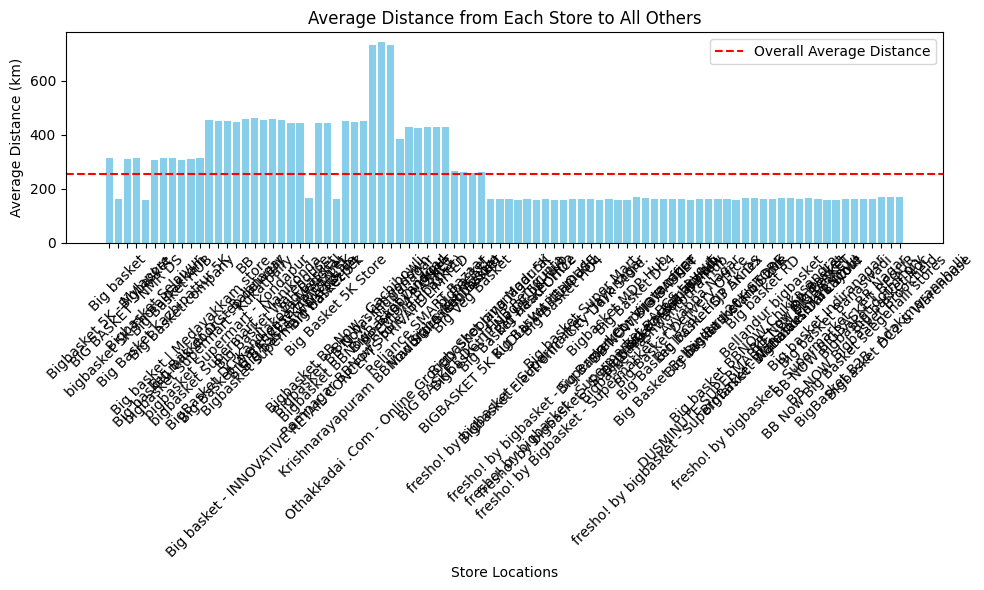

In [59]:
# Calculate average distance from each location to all others
distance_matrix['Average_Distance'] = distance_matrix.mean(axis=1)

# Find the store with the maximum average distance
max_avg_distance_store = distance_matrix['Average_Distance'].idxmax()
print(f"The location with the highest average distance is: {max_avg_distance_store}")

# Plot the average distances for each store
plt.figure(figsize=(10, 6))
plt.bar(distance_matrix.index, distance_matrix['Average_Distance'], color='skyblue')
plt.axhline(y=distance_matrix['Average_Distance'].mean(), color='r', linestyle='--', label='Overall Average Distance')

plt.title('Average Distance from Each Store to All Others')
plt.xlabel('Store Locations')
plt.ylabel('Average Distance (km)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

# Show plot
plt.show()

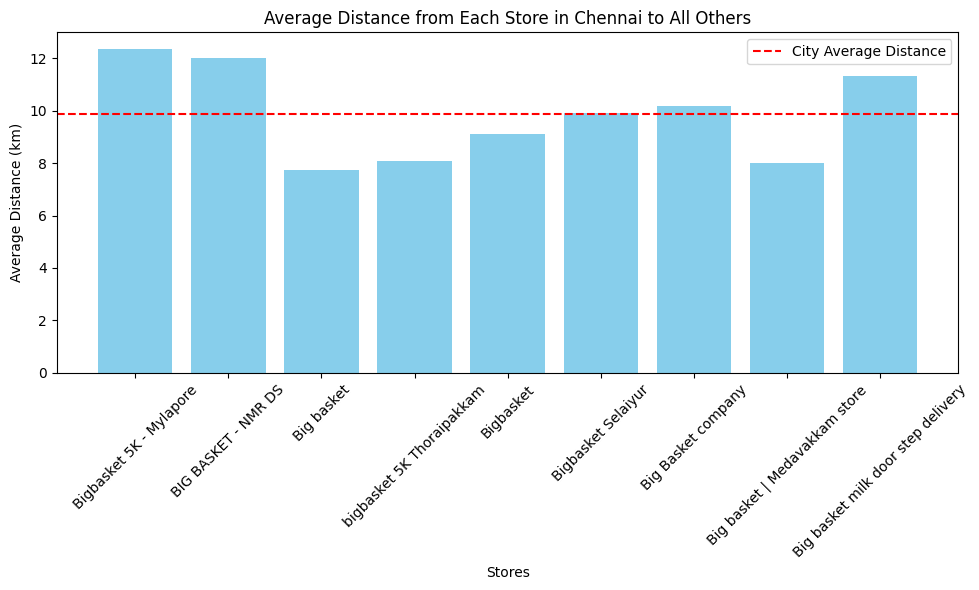

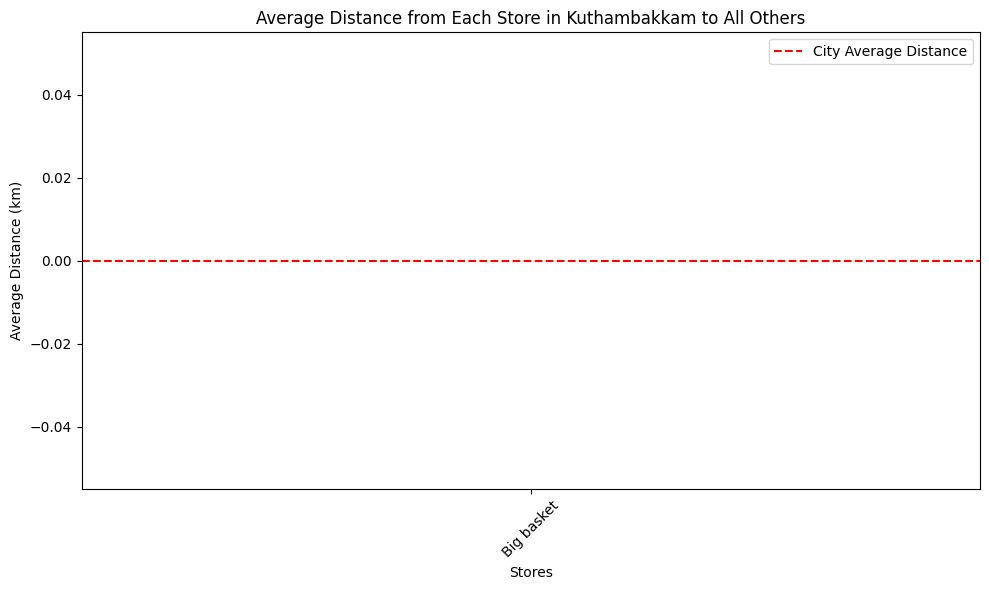

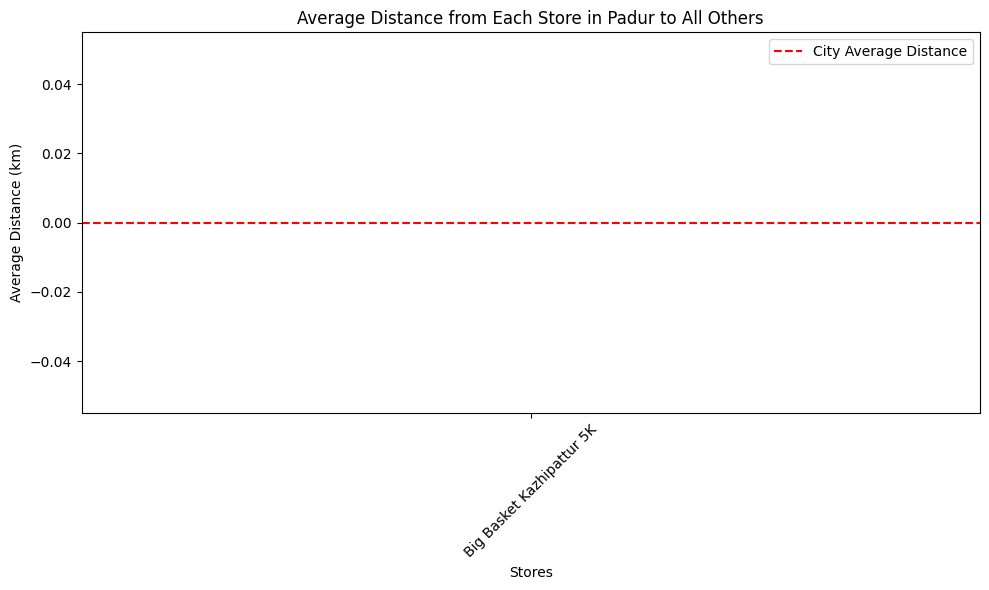

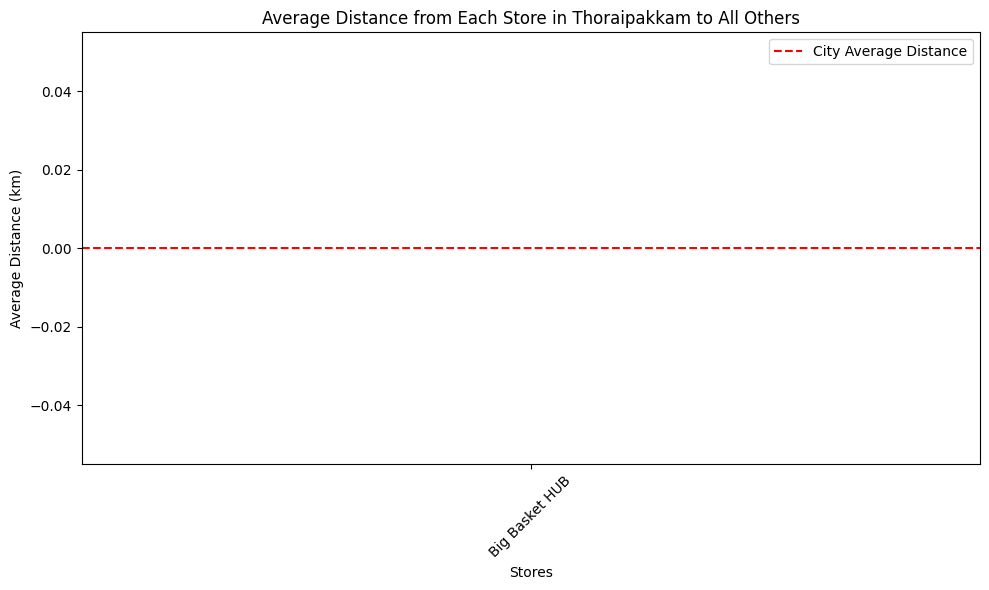

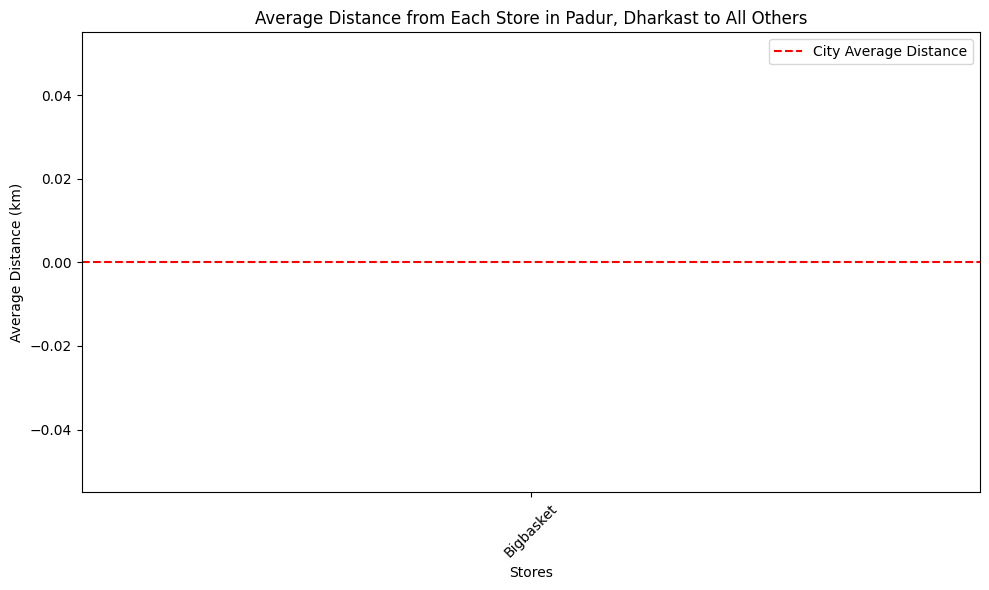

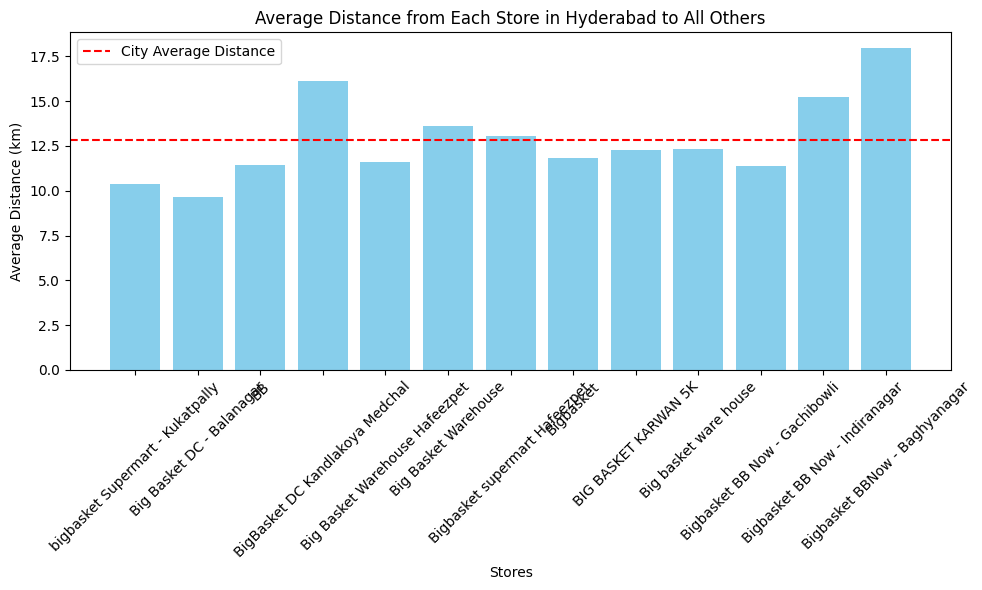

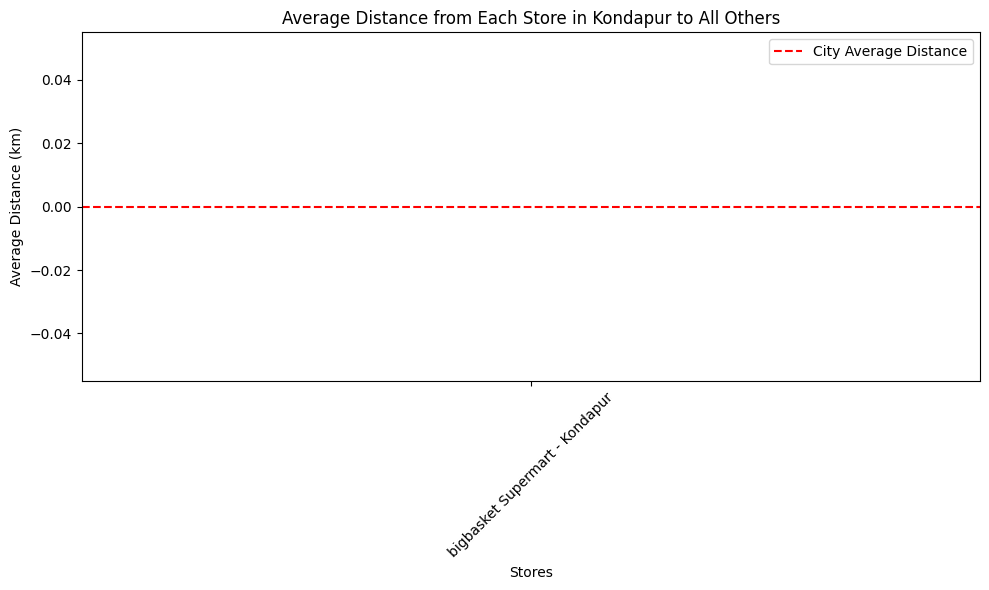

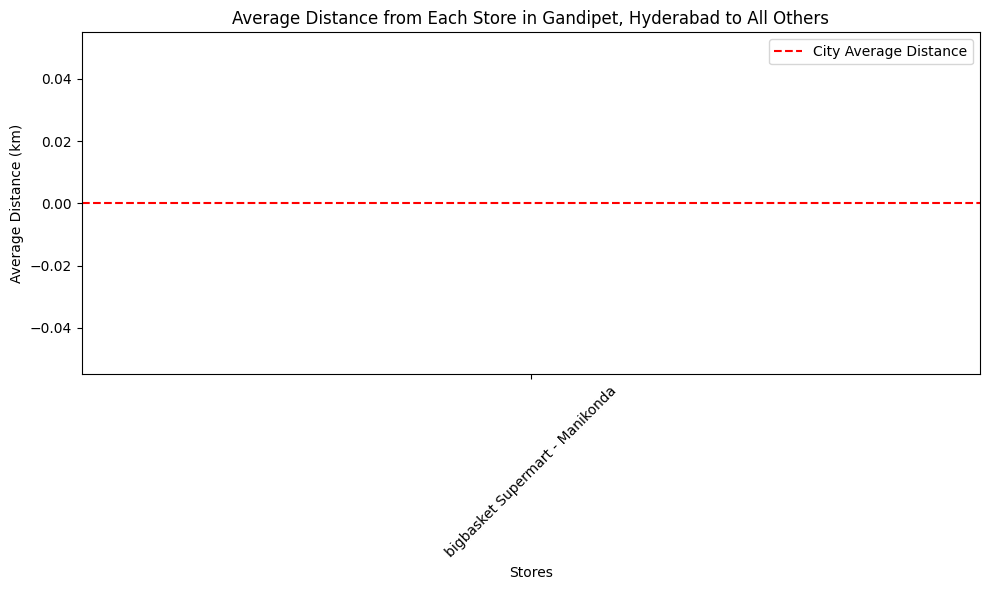

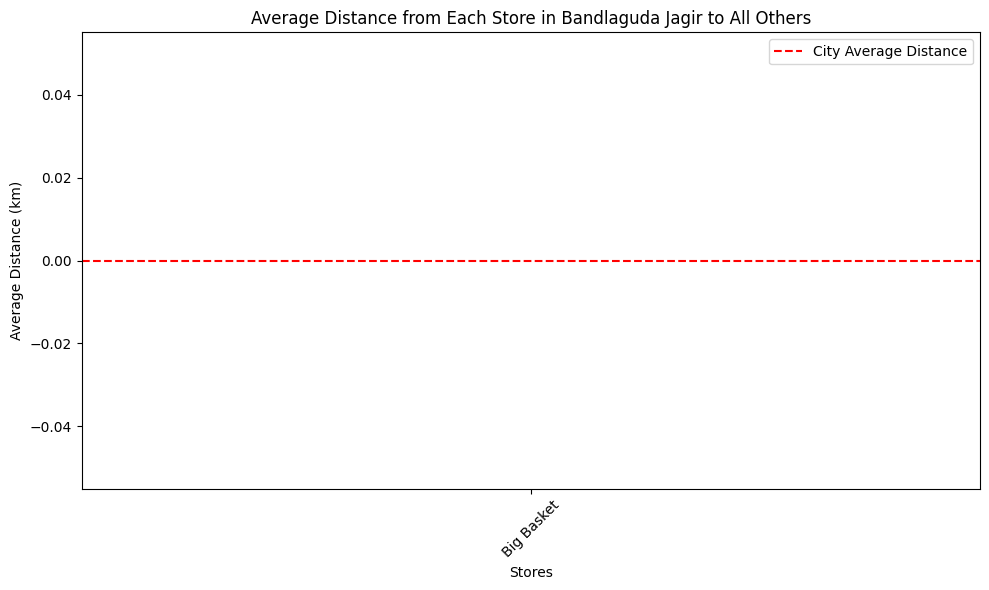

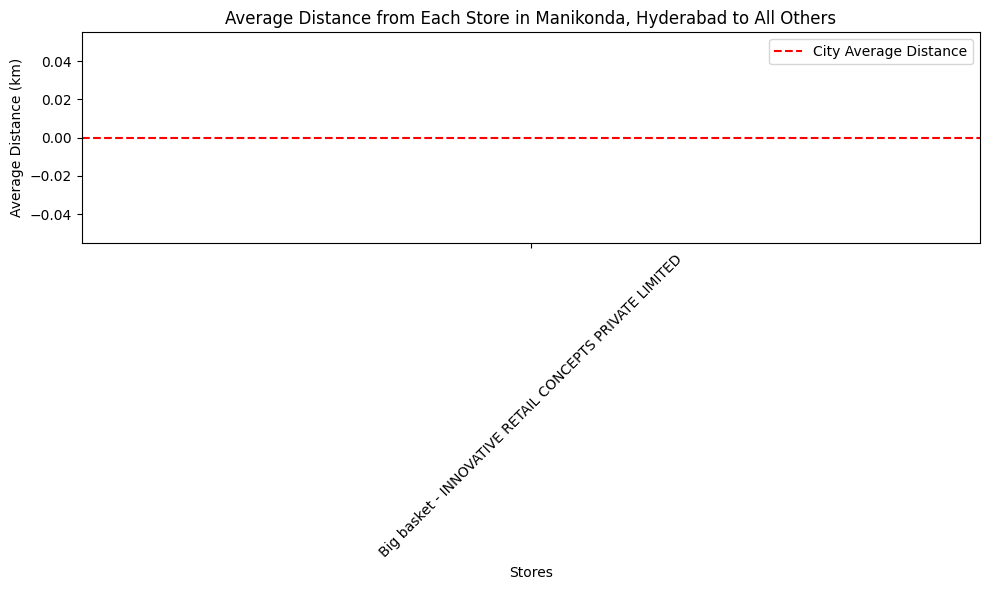

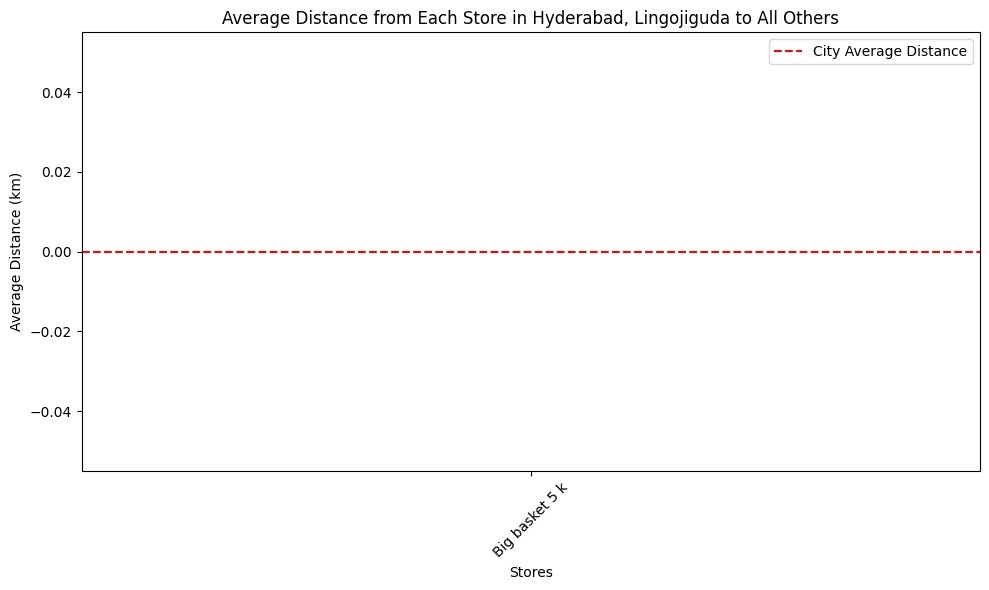

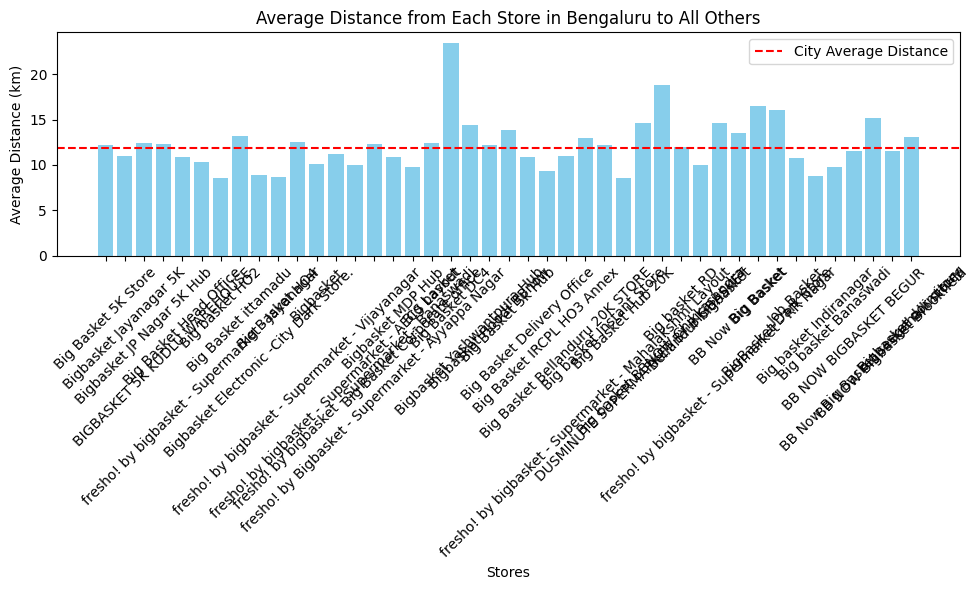

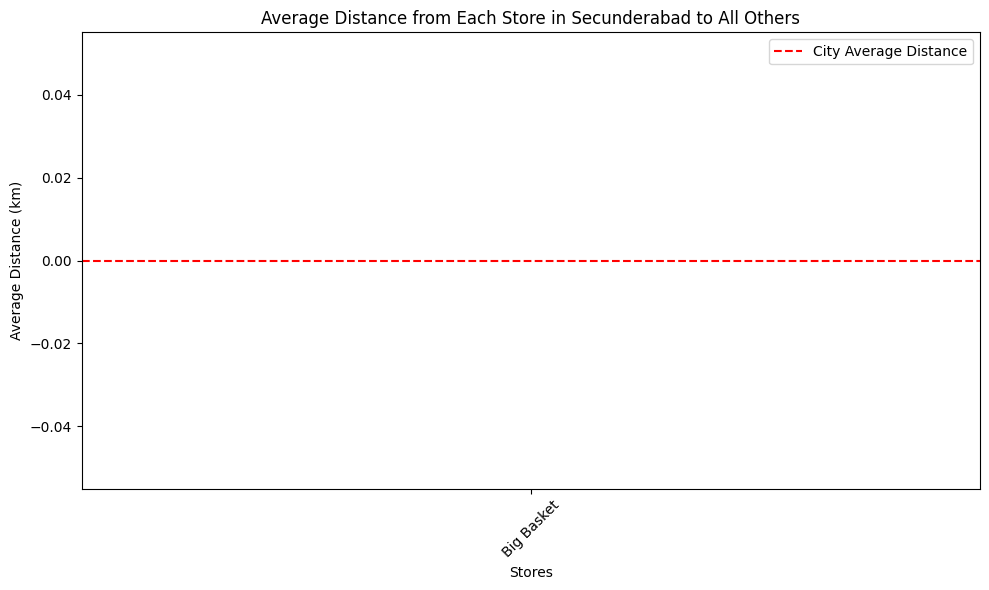

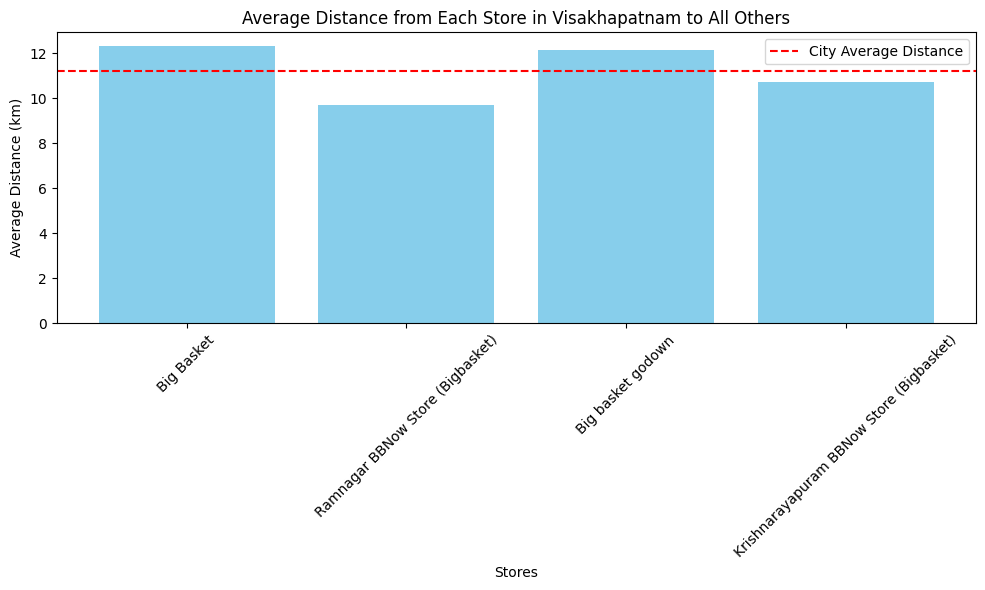

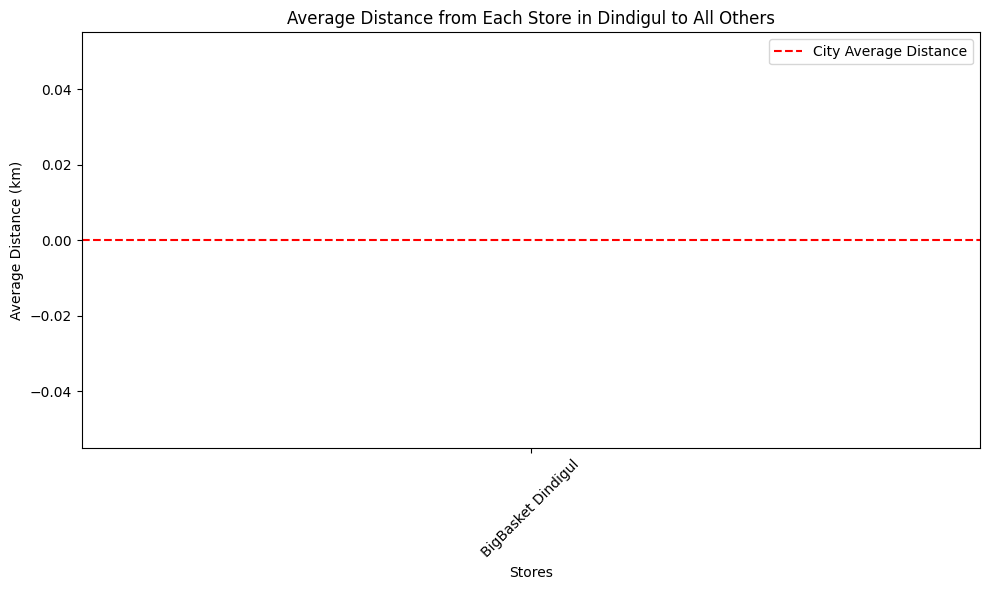

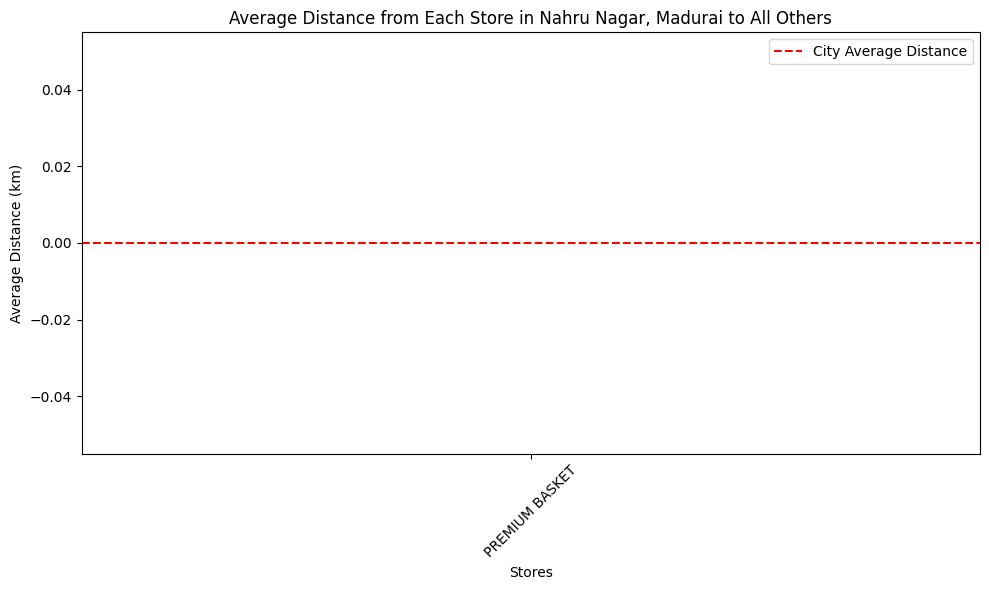

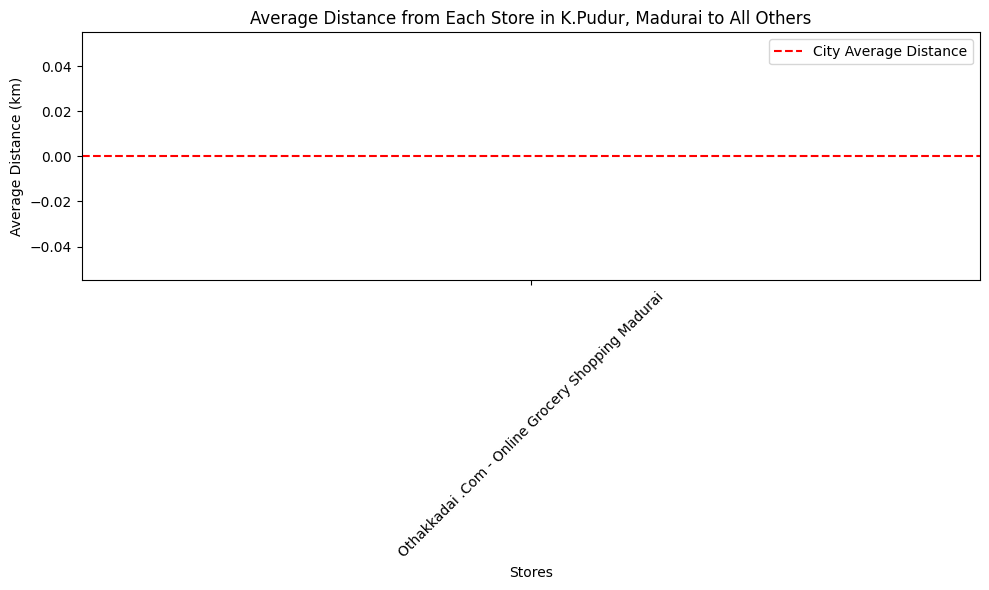

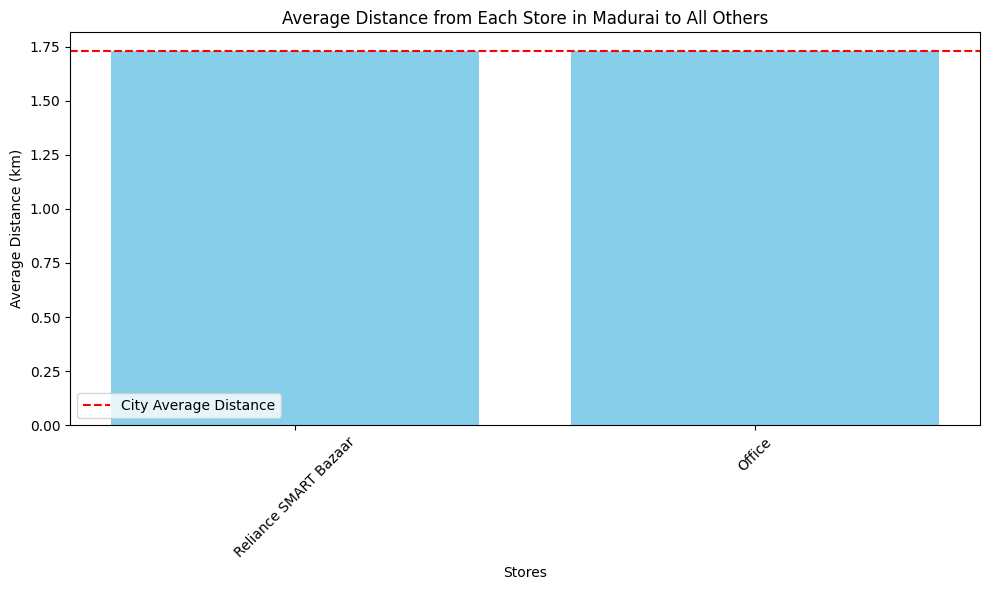

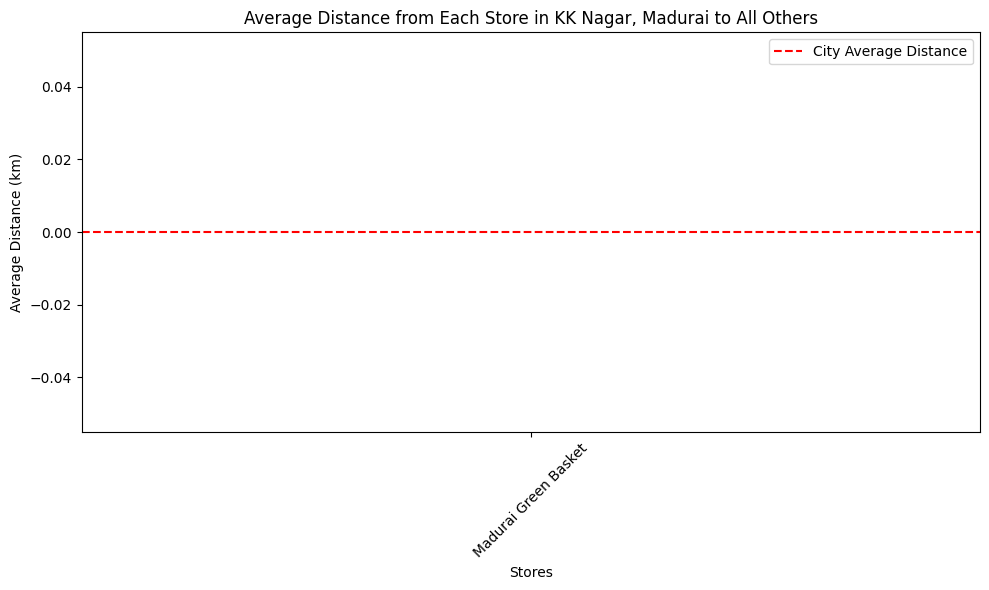

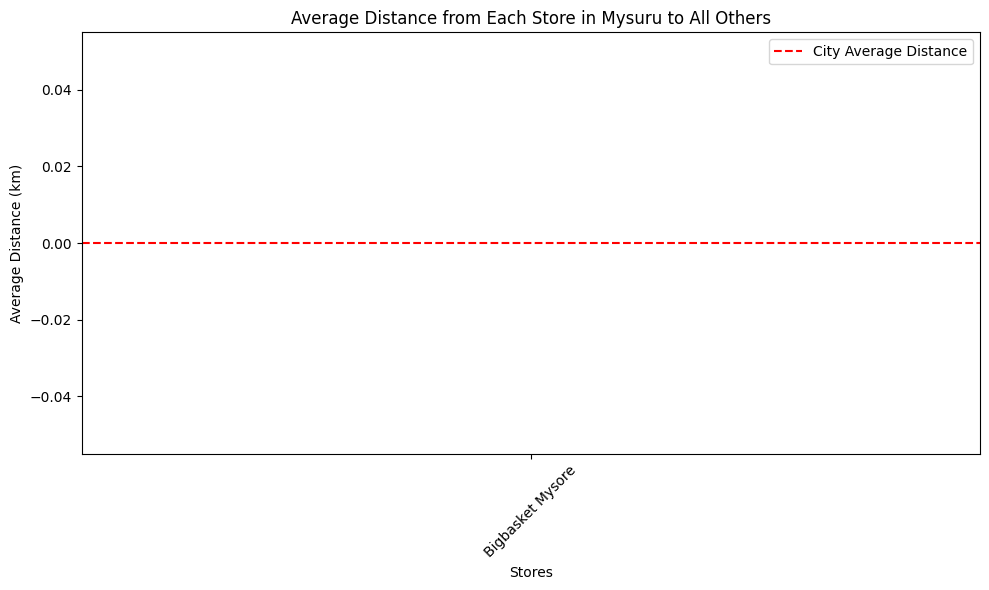

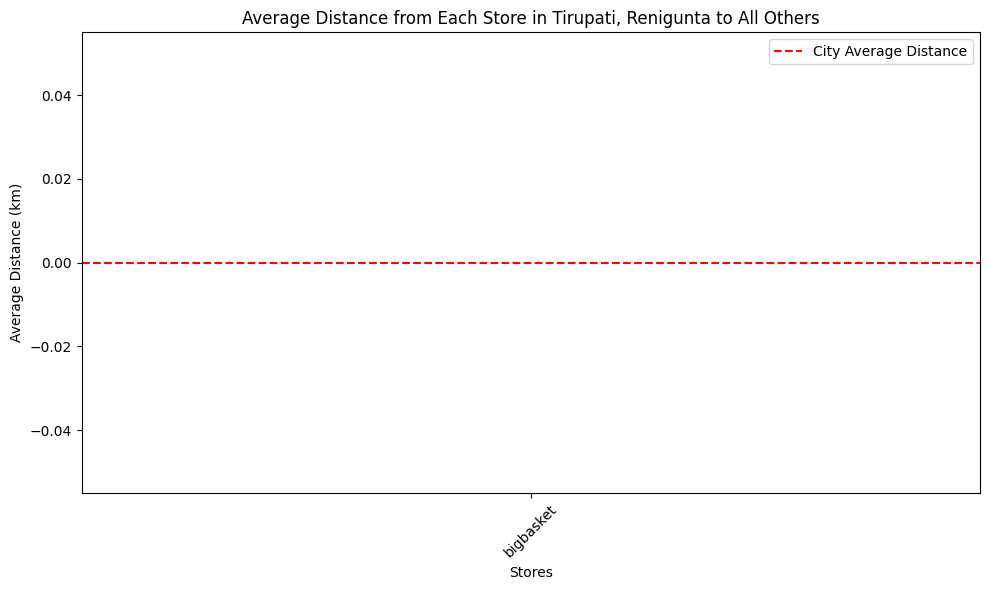

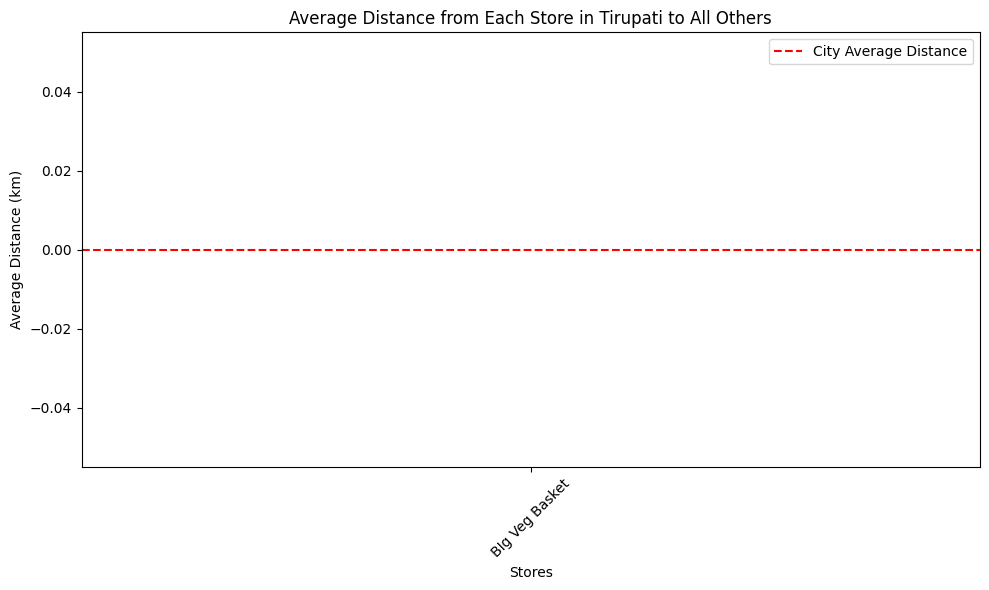

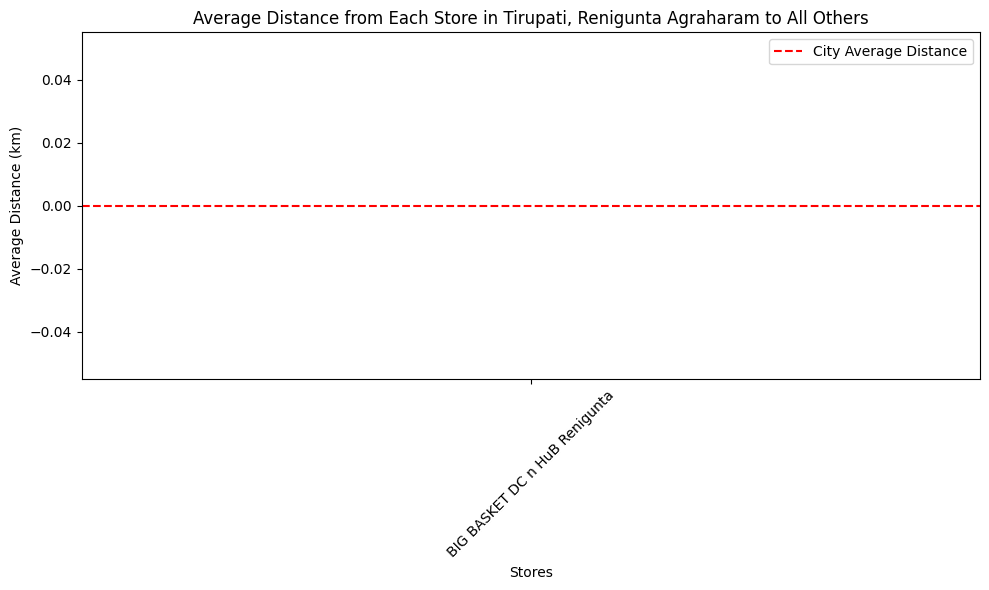

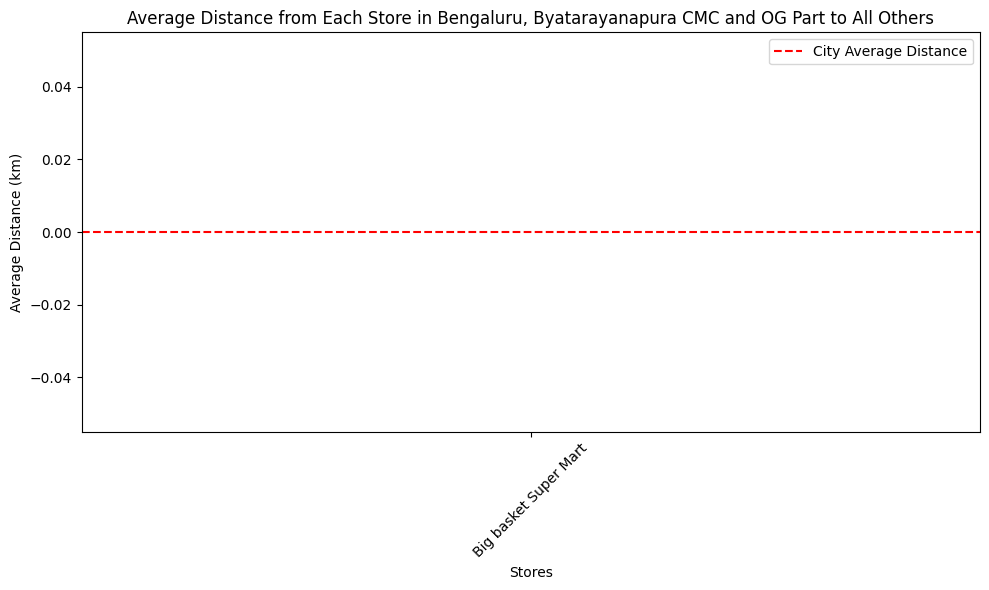

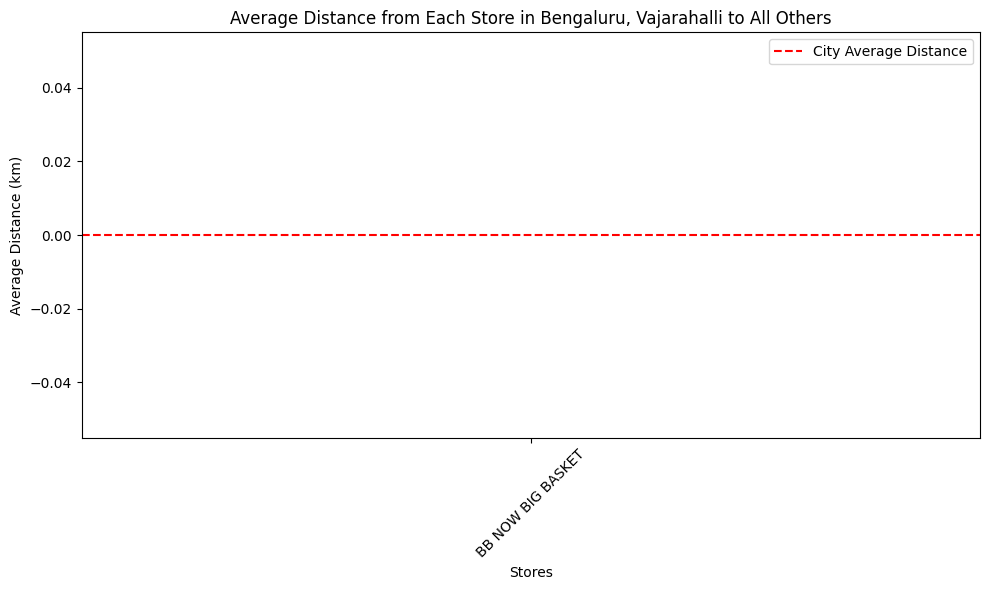

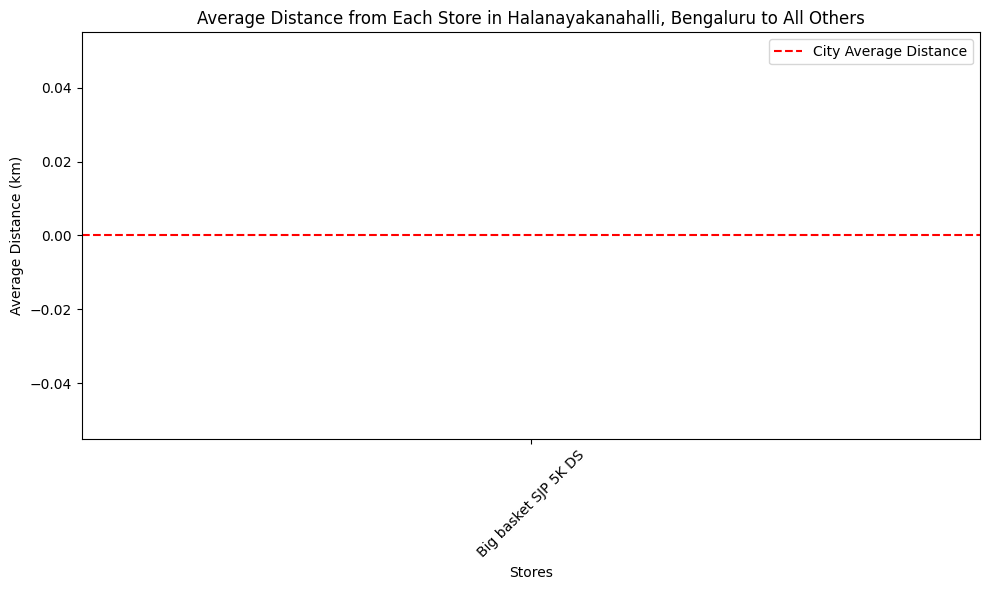

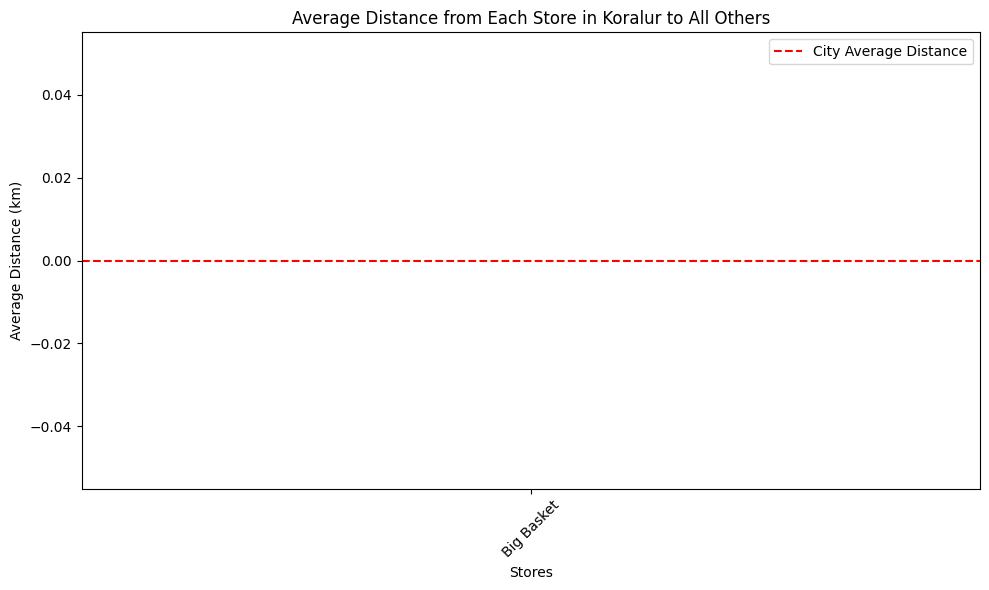

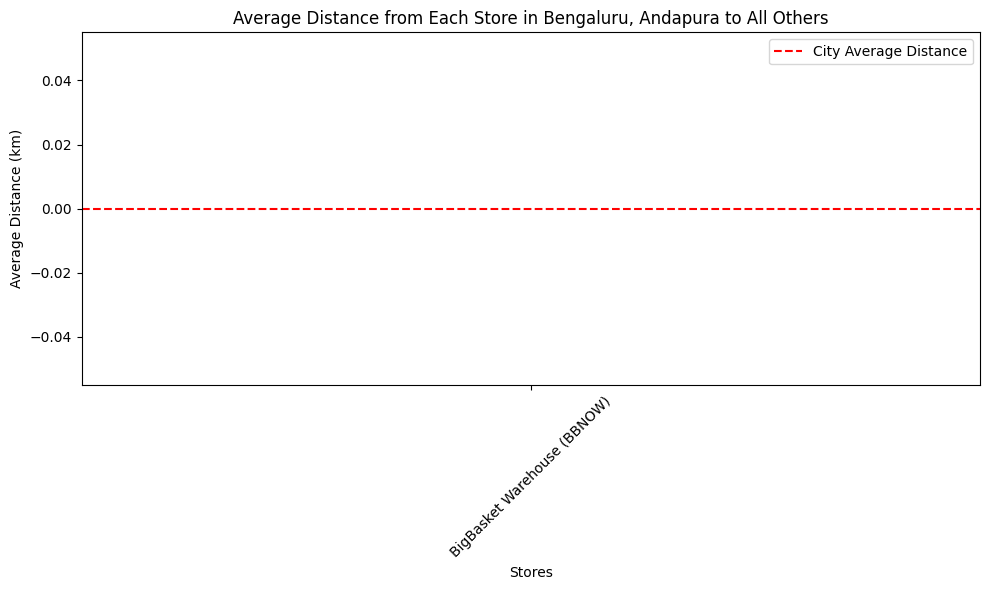

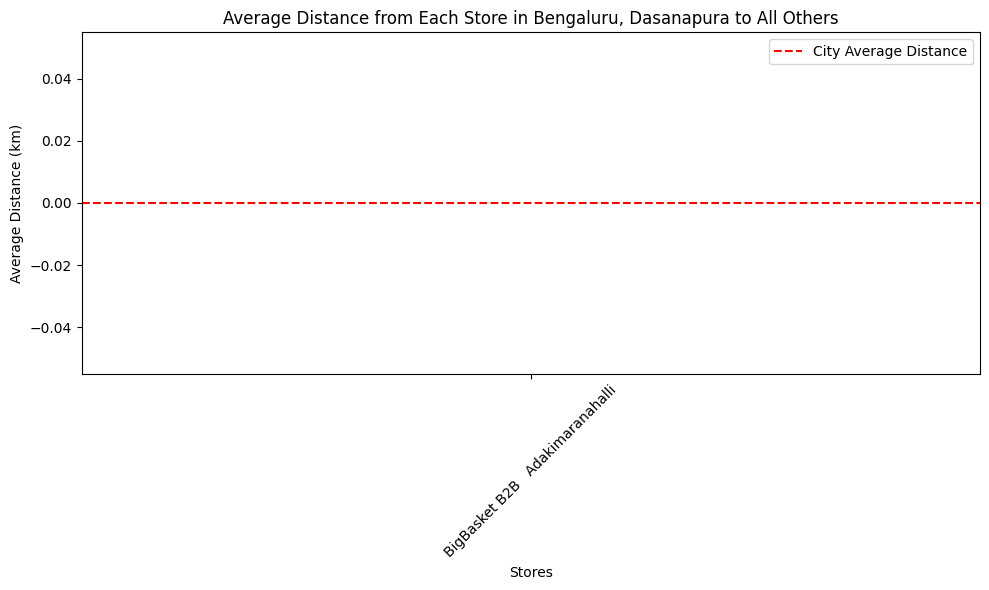

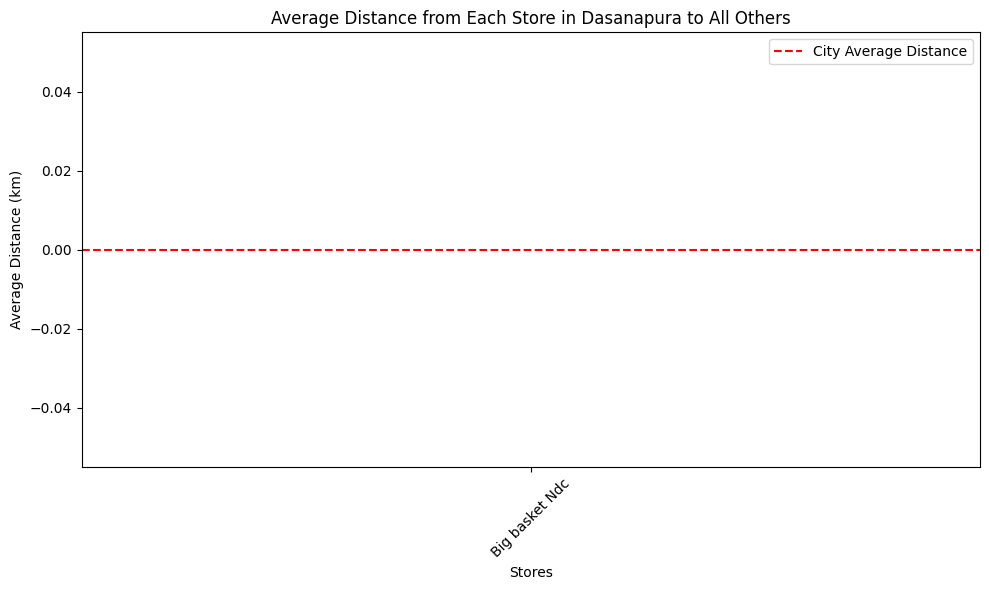

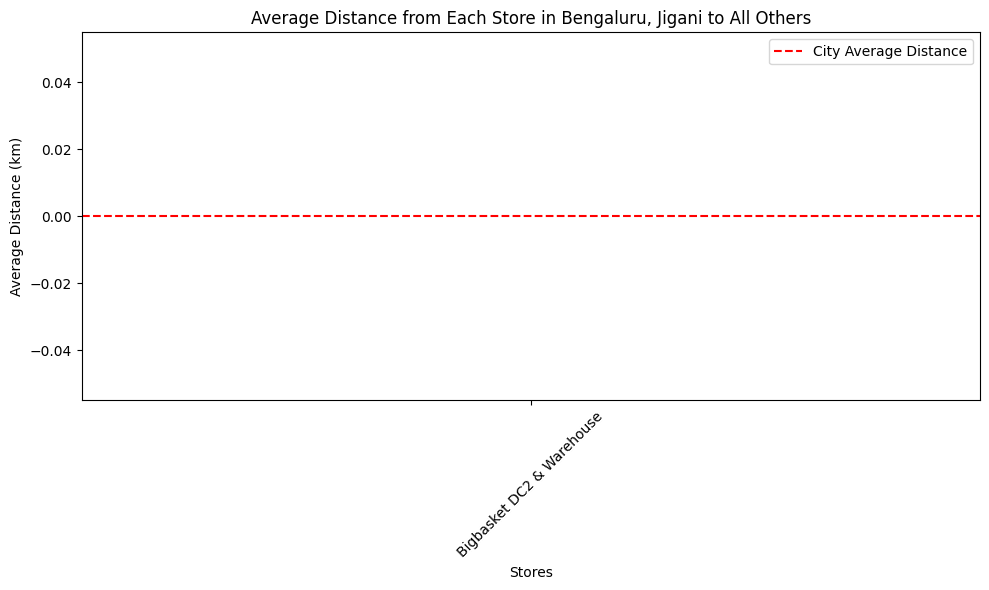

In [60]:
# Function to calculate distance matrix for a given city
def calculate_city_distance_matrix(city_df):
    n = len(city_df)
    distance_matrix = pd.DataFrame(index=city_df['Name'], columns=city_df['Name'])

    for i in range(n):
        for j in range(n):
            if i == j:
                distance_matrix.iloc[i, j] = 0
            else:
                dist = haversine(city_df.iloc[i]['Latitude'], city_df.iloc[i]['Longitude'],
                                 city_df.iloc[j]['Latitude'], city_df.iloc[j]['Longitude'])
                distance_matrix.iloc[i, j] = dist

    return distance_matrix.astype(float)

# Plotting function for a given city's stores
def plot_city_distances(city, city_distance_matrix):
    # Calculate the average distance for each store in the city
    city_distance_matrix['Average_Distance'] = city_distance_matrix.mean(axis=1)

    # Plot
    plt.figure(figsize=(10, 6))
    plt.bar(city_distance_matrix.index, city_distance_matrix['Average_Distance'], color='skyblue')
    plt.axhline(y=city_distance_matrix['Average_Distance'].mean(), color='r', linestyle='--', label='City Average Distance')

    plt.title(f'Average Distance from Each Store in {city} to All Others')
    plt.xlabel('Stores')
    plt.ylabel('Average Distance (km)')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()

    # Show plot
    plt.show()

# Loop through each city and plot distances for each city's stores
cities = df['City'].unique()
for city in cities:
    city_df = df[df['City'] == city]
    city_distance_matrix = calculate_city_distance_matrix(city_df)
    plot_city_distances(city, city_distance_matrix)

In [61]:
import numpy as np
from sklearn.cluster import DBSCAN

# Coordinates in radians (required for the haversine metric)
coords = np.radians(gdf[['Latitude', 'Longitude']].values)
KMS_PER_RADIAN = 6371.0

# Compare a few neighbourhood sizes (eps is given in km, then converted to radians)
for eps_km in [1, 2, 5, 10]:
    labels = DBSCAN(eps=eps_km / KMS_PER_RADIAN, min_samples=3,
                    metric='haversine', algorithm='ball_tree').fit_predict(coords)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"eps = {eps_km} km -> {n_clusters} clusters, {(labels == -1).sum()} noise points")

# Final model: stores within ~2 km of each other, at least 3 stores per cluster
EPS_KM = 2
db = DBSCAN(eps=EPS_KM / KMS_PER_RADIAN, min_samples=3,
            metric='haversine', algorithm='ball_tree')
gdf['cluster'] = db.fit_predict(coords)

print("\nStores per cluster (-1 = not in any cluster):")
print(gdf['cluster'].value_counts().sort_index())
gdf[['Name', 'City', 'cluster']].head(10)


eps = 1 km -> 2 clusters, 97 noise points
eps = 2 km -> 7 clusters, 73 noise points
eps = 5 km -> 9 clusters, 26 noise points
eps = 10 km -> 5 clusters, 7 noise points

Stores per cluster (-1 = not in any cluster):
cluster
-1    73
 0     6
 1     3
 2     5
 3     4
 4     5
 5     3
 6     4
Name: count, dtype: int64


,Name,City,cluster
0,Bigbasket 5K - Mylapore,Chennai,-1
1,Big basket,Kuthambakkam,-1
2,BIG BASKET - NMR DS,Chennai,-1
3,Big basket,Chennai,-1
4,bigbasket 5K Thoraipakkam,Chennai,-1
5,Bigbasket,Chennai,-1
6,Bigbasket Selaiyur,Chennai,-1
7,Big Basket Kazhipattur 5K,Padur,-1
8,Big Basket HUB,Thoraipakkam,-1
9,Bigbasket,"Padur, Dharkast",-1


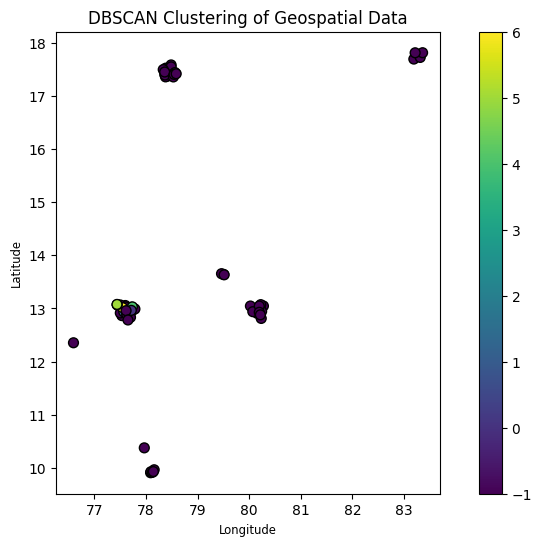

In [62]:
# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
gdf.plot(ax=ax, column='cluster', # Use column to specify the values for coloring
         cmap='viridis', # Use cmap for colormap
         edgecolor='black', markersize=50, legend=True)

# Adding labels
# Check if 'name' column exists before accessing it
if 'name' in gdf.columns:
    for idx, row in gdf.iterrows():
        ax.text(row.geometry.x, row.geometry.y, row['name'], fontsize=12, ha='right')

ax.set_title('DBSCAN Clustering of Geospatial Data')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

plt.show()

In [63]:
# Interactive map of stores coloured by DBSCAN cluster (grey = not in any cluster)
palette = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 'cadetblue',
           'darkgreen', 'pink', 'black', 'lightblue', 'beige']

m = folium.Map(location=[gdf['Latitude'].mean(), gdf['Longitude'].mean()], zoom_start=6)

for _, row in gdf.iterrows():
    label = int(row['cluster'])
    colour = 'gray' if label == -1 else palette[label % len(palette)]
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=6,
        color=colour,
        fill=True,
        fill_color=colour,
        fill_opacity=0.7,
        popup=f"{row['Name']} (cluster {label})"
    ).add_to(m)

# Zoom the map to fit all stores
m.fit_bounds([[gdf['Latitude'].min(), gdf['Longitude'].min()],
              [gdf['Latitude'].max(), gdf['Longitude'].max()]])

# Save map to HTML file and display it
m.save('clusters_map.html')
m


In [64]:
# Data: List of service options
service_options = [
    "No-contact delivery | Delivery | In-store pick-up | Same-day delivery",
    "No-contact delivery | Delivery | In-store pick-up | Same-day delivery",
    "No-contact delivery | Delivery | Same-day delivery",
    "Delivery",
    "No-contact delivery | Delivery | Same-day delivery",
    "Delivery | Same-day delivery",
    "Delivery | Same-day delivery",
    "No-contact delivery | Delivery | In-store pick-up | In-store shopping | Same-day delivery",
    "Delivery | Same-day delivery",
    "Delivery | Same-day delivery",
    "No-contact delivery | Delivery | Same-day delivery",
    "No-contact delivery | Delivery | In-store pick-up | In-store shopping | Same-day delivery",
    "No-contact delivery | Delivery | In-store pick-up | Same-day delivery",
    "No-contact delivery | Delivery | Same-day delivery",
    "Delivery",
    "Delivery | In-store pick-up | In-store shopping | Same-day delivery",
    "Delivery | Same-day delivery",
    "Delivery",
    "Delivery | Same-day delivery",
    "Delivery | In-store shopping | Same-day delivery",
    "Delivery",
    "No-contact delivery | Delivery | In-store pick-up | Same-day delivery",
    "Delivery | Same-day delivery",
    "Delivery"
]

# Convert list to DataFrame
df = pd.DataFrame({'services': service_options})

# Split the services into separate rows
df = df['services'].str.split(' \| ', expand=True).stack().reset_index(level=1, drop=True).to_frame(name='service')

# Count occurrences of each service
service_counts = df['service'].value_counts()

# Print service counts
print("Service Counts:")
print(service_counts)



Service Counts:
service
Delivery               24
Same-day delivery      19
No-contact delivery    10
In-store pick-up        7
In-store shopping       4
Name: count, dtype: int64


<>:33: SyntaxWarning: invalid escape sequence '\|'
<>:33: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_1377/1060526792.py:33: SyntaxWarning: invalid escape sequence '\|'
  df = df['services'].str.split(' \| ', expand=True).stack().reset_index(level=1, drop=True).to_frame(name='service')


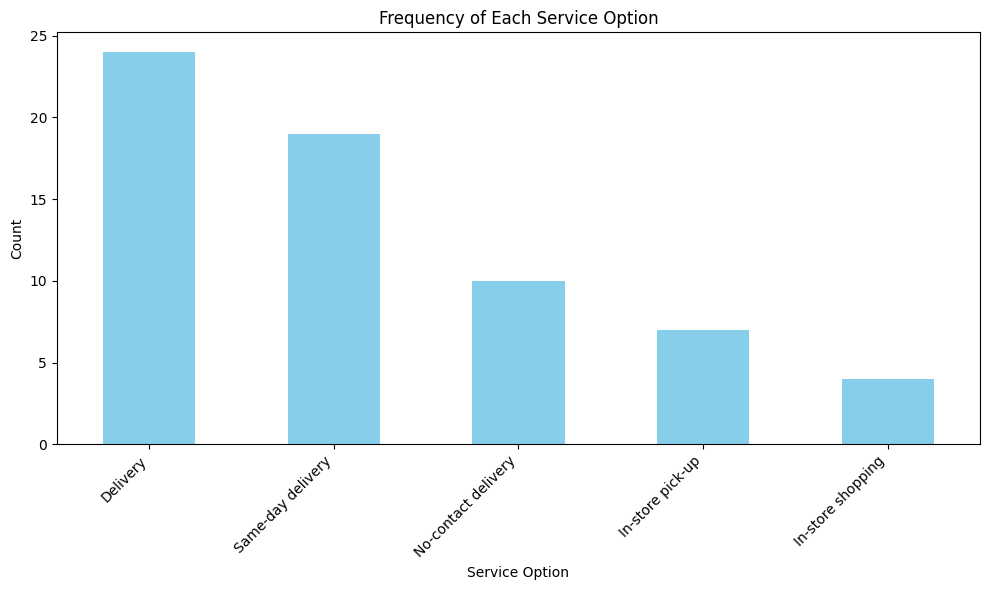

In [65]:
# Plot the results
plt.figure(figsize=(10, 6))
service_counts.plot(kind='bar', color='skyblue')
plt.title('Frequency of Each Service Option')
plt.xlabel('Service Option')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()